# Анализ тестовой выборки и результатов BLIND (NMRexp)

Ноутбук повторяет статистики из статьи BLIND (ChemRxiv 10.26434/chemrxiv.15006080: Fig. 3, S3, S6, S8, S10, S11, S13–S15, Tables S2, S5, S6) и добавляет анализ неопределённости.

**Части:**
- **A.** Состав теста: молекулы, элементы, размеры, спектры (результаты модели не нужны).
- **B.** Метрики top-1 и top-10 по модальностям, парное сравнение запусков (McNemar).
- **C.** Точность в зависимости от сложности: число атомов, масса, элементы, стереоцентры, согласованность спектров.
- **D.** Ошибки: насколько неверные ответы похожи на правильные (Танимото).
- **E.** Top-10: уникальные кандидаты, ранг правильного ответа, стереоизомеры.
- **F.** Неопределённость: P(первый кандидат верен | разница log-likelihood с вторым), калибровка, AUC, risk–coverage.

### Термины, которые встречаются везде
- **Модальность** — какие спектры поданы на вход: `Only C` — только 13C, `Only H` — только 1H, `Both` — оба. `Overall` — все примеры вместе.
- **Пример (case)** — одна пара спектров одной молекулы. У молекулы с несколькими спектрами примеров несколько.
- **Exact match (точное совпадение)** — предсказанная структура совпадает с правильной вместе со стереохимией (сравниваются канонические SMILES RDKit).
- **Topological match (совпадение без стереохимии)** — совпадает граф молекулы, стереохимия не учитывается.
- **Top-1 (жадно)** — один ответ из `evaluate.py`: на каждом шаге берётся самый вероятный токен.
- **Top-10** — из `evaluate_top_n.py`: 10 сэмплов, повторы схлопываются, правильный ответ ищется среди всех уникальных кандидатов.
- **log-likelihood (score)** — сумма логарифмов вероятностей токенов SMILES-кандидата. Всегда ≤ 0, чем ближе к 0, тем модель увереннее. Разница 1 по score означает, что один кандидат в e ≈ 2.7 раза вероятнее другого.
- **Лучший кандидат (first)** — кандидат из сэмплов с наибольшим log-likelihood.
- **95% ДИ** — доверительный интервал Уилсона для доли; полоса вокруг линий на графиках.

### Как добавить запуск
Другая модель или другой набор модальностей на входе: допишите его в `RUNS`. Все таблицы и графики группируются по запуску и модальности; на графиках цвет — модальность, стиль линии — запуск.

```bash
python evaluate.py       --checkpoint ... --tokenizer-path data/nmrexp/processed/smiles_tokenizer.model --data-path data/nmrexp/processed/test.jsonl.gz --output-json results/....json
python evaluate_top_n.py --checkpoint ... --tokenizer-path data/nmrexp/processed/smiles_tokenizer.model --data-path data/nmrexp/processed/test.jsonl.gz --output-json results/..._top_10.json
```
Для части F лучше запускать `evaluate_top_n.py` с `--num-samples 50` и больше: при 10 сэмплах у уверенных спектров часто остаётся один уникальный кандидат, и второго log-likelihood нет.

In [1]:
# ---- настройки ----
RUNS = {
    # имя запуска: {"top1": вывод evaluate.py, "topn": вывод evaluate_top_n.py}; любой из двух можно не указывать
    "with J (epoch 199)": {"top1": "results/results_J_199.json", "topn": "results/results_J_199_top_10.json"},
}
TEST_PATH = "data/nmrexp/processed/test.jsonl.gz"
TOKENIZER_PATH = "data/nmrexp/processed/smiles_tokenizer.model"
FLAGGED_PATH = "data/nmrexp/processed/test_flagged.json"  # пишет analysis/check_leakage.py
EXCLUDE_FLAGGED = False  # True: убрать тестовые молекулы, похожие на train/val (таутомеры, изотопологи, одинаковые спектры)
TOP_N = 10
MIN_COUNT = 30  # точки графиков, где примеров меньше, не рисуются

In [2]:
import json, os, sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "analysis").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "analysis"))
import test_analysis_lib as L

pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "legend.fontsize": 7, "axes.titlesize": 10, "axes.labelsize": 9})
LEGEND_TITLE = "запуск | модальность"

## A. Состав тестовой выборки

Здесь используется только файл теста `test.jsonl.gz`, результаты модели не нужны.

**Что печатается ниже:**
- **молекул** — уникальные SMILES в тесте; **спектров 13C / 1H** — сколько спектров каждого типа.
- **ожидаемые примеры оценки** — сколько пар получится при оценке: для молекулы с k спектрами 13C и m спектрами 1H будет min(k, m) примеров `Both` и |k − m| примеров `Only C` или `Only H` (так собирает пары `EvaluationDataset`).
- **помечено check_leakage.py** — тестовые молекулы, похожие на train/val по мягким критериям: `inchikey` — тот же InChIKey (таутомер или другая запись той же молекулы), `skeleton` — тот же скелет (обычно дейтерированный аналог), `spectrum` — у молекулы из train/val точно такой же спектр.

In [4]:
spectra = L.read_test_records(TEST_PATH)
flagged = json.load(open(FLAGGED_PATH)) if Path(FLAGGED_PATH).exists() else {}
if EXCLUDE_FLAGGED:
    spectra = spectra[~spectra["smiles"].isin(flagged)]

per_mol = spectra.groupby(["smiles", "spectrum_type"]).size().unstack(fill_value=0)
per_mol = per_mol.reindex(columns=["C_NMR", "H_NMR"], fill_value=0)
pairs = pd.DataFrame({
    "Both": np.minimum(per_mol["C_NMR"], per_mol["H_NMR"]),
    "Only C": (per_mol["C_NMR"] - per_mol["H_NMR"]).clip(lower=0),
    "Only H": (per_mol["H_NMR"] - per_mol["C_NMR"]).clip(lower=0),
}).sum()
print(f"молекул: {len(per_mol)}; спектров 13C: {per_mol['C_NMR'].sum()}, 1H: {per_mol['H_NMR'].sum()}")
print("ожидаемые примеры оценки по модальностям:", pairs.to_dict())
print(f"в среднем спектров на молекулу (среди молекул, у которых есть такой тип): 13C {per_mol['C_NMR'][per_mol['C_NMR']>0].mean():.2f}, 1H {per_mol['H_NMR'][per_mol['H_NMR']>0].mean():.2f}")
print(f"помечено check_leakage.py: {len(flagged)} молекул ({len(flagged)/max(len(per_mol),1):.2%}); исключены из анализа: {EXCLUDE_FLAGGED}")
print("причины пометки (молекула может иметь несколько):", dict(Counter(r.split(':')[0] for v in flagged.values() for r in {x.split(':')[0] + ':' for x in v})))

молекул: 133558; спектров 13C: 127935, 1H: 147753
ожидаемые примеры оценки по модальностям: {'Both': 119987, 'Only C': 7948, 'Only H': 27766}
в среднем спектров на молекулу (среди молекул, у которых есть такой тип): 13C 1.14, 1H 1.17
помечено check_leakage.py: 0 молекул (0.00%); исключены из анализа: False
причины пометки (молекула может иметь несколько): {}


### Рис. A1. Сколько спектров приходится на одну молекулу (аналог Fig. S10)

- **Ось X** — число спектров данного типа у молекулы.
- **Ось Y** — число молекул, логарифмическая шкала.
- Синие столбцы — спектры 13C, красные — 1H. Учитываются только молекулы, у которых есть хотя бы один спектр этого типа.

Почти у всех молекул один спектр каждого типа: модель учится по одному измерению на соединение.

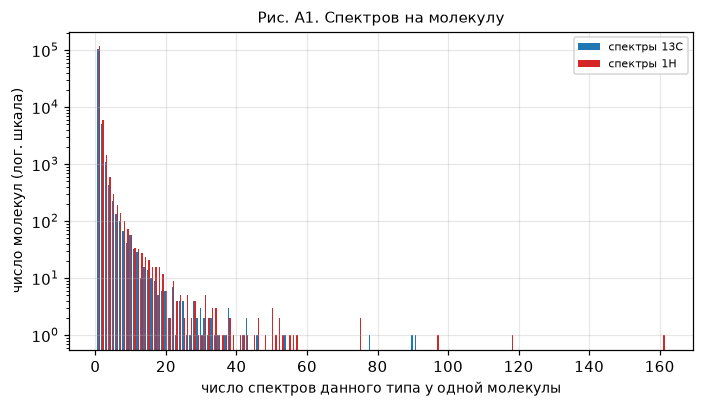

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for col, color, name in (("C_NMR", "#1f77b4", "13C"), ("H_NMR", "#d62728", "1H")):
    vc = per_mol[col][per_mol[col] > 0].value_counts().sort_index()
    ax.bar(vc.index + (0.2 if col == "H_NMR" else -0.2), vc.values, width=0.4, color=color, label=f"спектры {name}")
ax.set_yscale("log")
ax.set_xlabel("число спектров данного типа у одной молекулы")
ax.set_ylabel("число молекул (лог. шкала)")
ax.set_title("Рис. A1. Спектров на молекулу")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### A2. Молекулы теста: размер, масса, гетероатомы, циклы, стереоцентры

**Таблица** — описательная статистика по уникальным молекулам теста. Строки — признаки:
- `heavy_atoms` — тяжёлые атомы (все, кроме H);
- `n_carbon` — атомы углерода;
- `mol_weight` — молекулярная масса, Да;
- `n_heteroatoms` — атомы, кроме C и H;
- `n_rings` и `n_aromatic_rings` — все и ароматические циклы;
- `n_stereocenters` — стереоцентры, включая неуказанные в SMILES;
- `n_species` — число частиц в SMILES (соли и смеси записываются через «.»).

Столбцы: `count` — число молекул, `mean` и `std` — среднее и стандартное отклонение, `min`/`max`, а `5%…95%` — перцентили (например, 95% — значение, ниже которого 95% молекул).

**Рис. A2** — распределения тех же признаков. Ось Y — число молекул; на последних двух панелях шкала логарифмическая, потому что большие значения редки. Самые большие значения (последние 0.1%) собраны в крайний правый столбец, масса обрезана на 1200 Да.

молекул, которые RDKit не смог разобрать: 0


,count,mean,std,min,5%,25%,50%,75%,95%,max
heavy_atoms,133558.0000,23.8265,8.3685,3.0000,13.0000,18.0000,23.0000,28.0000,39.0000,170.0000
n_carbon,133558.0000,19.2416,7.2457,1.0000,10.0000,14.0000,18.0000,23.0000,32.0000,170.0000
mol_weight,133558.0000,341.3378,117.8062,56.0640,188.2510,260.0740,324.1810,401.4620,550.6383,2158.7980
n_heteroatoms,133558.0000,4.5849,2.5418,0.0000,1.0000,3.0000,4.0000,6.0000,9.0000,37.0000
n_rings,133558.0000,2.8245,1.5445,0.0000,1.0000,2.0000,3.0000,4.0000,6.0000,70.0000
n_aromatic_rings,133558.0000,2.1411,1.3456,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,28.0000
n_stereocenters,133558.0000,0.8638,1.2717,0.0000,0.0000,0.0000,1.0000,1.0000,3.0000,21.0000
n_species,133558.0000,1.0035,0.0607,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,4.0000


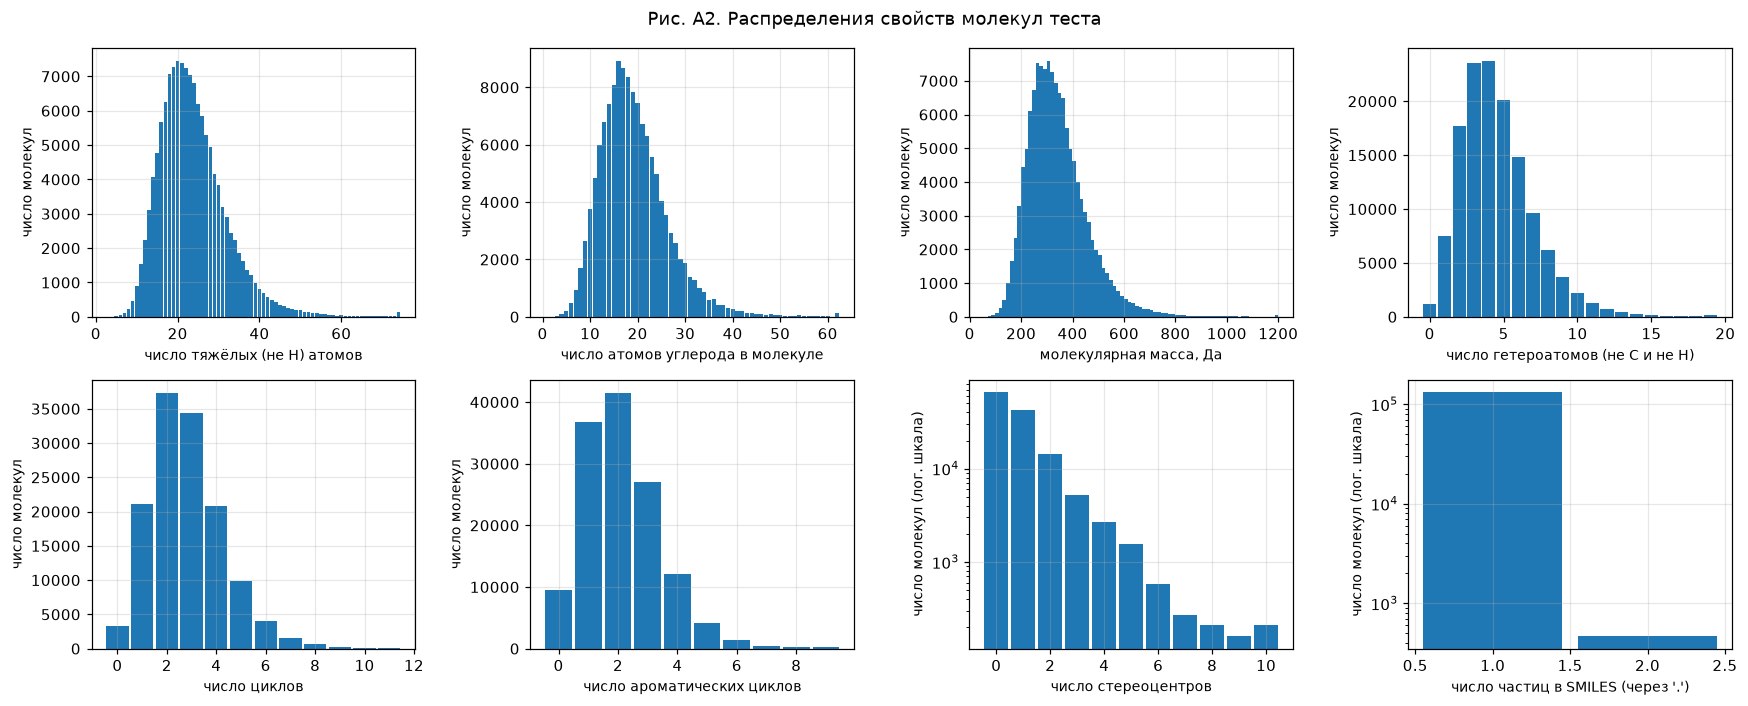

In [5]:
descriptors = L.descriptor_table(per_mol.index)
mol = descriptors.loc[per_mol.index]
print("молекул, которые RDKit не смог разобрать:", mol["heavy_atoms"].isna().sum())
cols = ["heavy_atoms", "n_carbon", "mol_weight", "n_heteroatoms", "n_rings", "n_aromatic_rings", "n_stereocenters", "n_species"]
display(mol[cols].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.flat, cols):
    data = mol[col].dropna()
    if col == "mol_weight":
        ax.hist(data.clip(upper=1200), bins=80)
    else:
        vc = data.astype(int).clip(upper=int(data.quantile(0.999))).value_counts().sort_index()
        ax.bar(vc.index, vc.values, width=0.9)
    ax.set_xlabel(L.LABELS.get(col, col)); ax.set_ylabel("число молекул")
    ax.grid(alpha=0.3)
axes[1, 2].set_yscale("log"); axes[1, 3].set_yscale("log")
axes[1, 2].set_ylabel("число молекул (лог. шкала)"); axes[1, 3].set_ylabel("число молекул (лог. шкала)")
fig.suptitle("Рис. A2. Распределения свойств молекул теста")
plt.tight_layout(); plt.show()

### A3. Элементный состав (аналог Table S2) и категории молекул (как в Fig. 3C)

- **Первая таблица:** сколько молекул теста содержит каждый элемент. Один раз на молекулу, независимо от числа атомов.
- **Вторая таблица:** категории, по которым в части C считается точность. Строка «молекул» — сколько молекул в категории, «доля» — какая это часть теста. Категории пересекаются: молекула с N и Cl попадёт и в «contains N», и в «contains Cl».
  - `C,H only` — только углерод и водород;
  - `C,H,O only` — C, H и обязательно O, других элементов нет; `C,H,N,O only` — аналогично с N;
  - `contains X` — есть хотя бы один атом X;
  - `rare element` / `metal` — элемент вне обычного органического набора (металлы и т. п.);
  - `charged` — есть атом с формальным зарядом;
  - `multiple species` — в SMILES несколько частиц (соль, комплекс, смесь).

In [6]:
elements = Counter(e for s in mol["elements"].dropna() for e in s.split())
display(pd.Series(elements, name="молекул с элементом").sort_values(ascending=False).to_frame().T)

cats = L.element_categories(mol)
cat_counts = pd.Series({k: int(v.sum()) for k, v in cats.items()}, name="молекул")
display(pd.DataFrame({"молекул": cat_counts, "доля": cat_counts / len(mol)}).T)
print(f"заряженные: {mol['charged'].mean():.2%}; несколько частиц ('.'): {(mol['n_species'] > 1).mean():.2%}; "
      f"со стереохимией, указанной в SMILES: {(mol['n_specified_stereo'] > 0).mean():.2%}; с E/Z-изомерией двойной связи: {mol['has_double_bond_stereo'].mean():.2%}")

,C,H,O,N,S,F,Cl,Br,Si,P,I,B,Se,Sn,Fe,Ge,Te,Au,Cu,Bi,Pd,Sb,Ir,Na,Al,Zn,Pt,Ni,As,Ts,Ru,K,Hg
молекул с элементом,133558,133558,116019,86948,28476,24783,14053,11239,6876,3574,3202,2782,1137,114,105,96,47,9,8,8,5,5,4,3,3,3,3,2,2,1,1,1,1


,"C,H only","C,H,O only","C,H,N,O only",contains N,contains O,contains S,contains P,contains F,contains Cl,contains Br,contains I,contains Si,contains B,contains Se,contains halogen,rare element,metal,charged,multiple species
молекул,1164.0000,18366.0000,39012.0000,86948.0000,116019.0000,28476.0000,3574.0000,24783.0000,14053.0000,11239.0000,3202.0000,6876.0000,2782.0000,1137.0000,48038.0000,149.0000,149.0000,9060.0000,465.0000
доля,0.0087,0.1375,0.2921,0.6510,0.8687,0.2132,0.0268,0.1856,0.1052,0.0842,0.0240,0.0515,0.0208,0.0085,0.3597,0.0011,0.0011,0.0678,0.0035


заряженные: 6.78%; несколько частиц ('.'): 0.35%; со стереохимией, указанной в SMILES: 25.36%; с E/Z-изомерией двойной связи: 12.75%


### A4. Спектры: число сигналов, интегралы и их согласованность со структурой

**Рис. A3** — шесть гистограмм по всем спектрам теста. Ось Y везде — число спектров в логарифмической шкале; значения за краями диапазона собраны в крайние столбцы.
1. Число сигналов (пиков) в спектре 13C.
2. Число сигналов в спектре 1H.
3. Сумма интегралов всех сигналов 1H, то есть сколько протонов «видно» в спектре.
4. **13C: сигналов − атомов C.** Определение из статьи (Fig. S6). 0 — сигналов столько же, сколько атомов углерода. Отрицательные значения — часть атомов совпала по сдвигу или эквивалентна по симметрии. Положительные — сигналов больше, чем атомов (ошибка или медленный обмен конформеров).
5. **13C: сигналов − неэквивалентных атомов C.** То же, но ожидаемое число учитывает симметрию молекулы. Например, у бензола 6 атомов C, но один неэквивалентный. 0 означает полностью согласованный спектр.
6. **1H: сумма интегралов − атомов H** (аналог Fig. S8). 0 — интегралы точно соответствуют числу протонов. Отрицательные значения обычно возникают из-за обменных протонов OH и NH, которые часто не видны.

Под рисунком напечатаны доли согласованных спектров и диапазоны химических сдвигов.

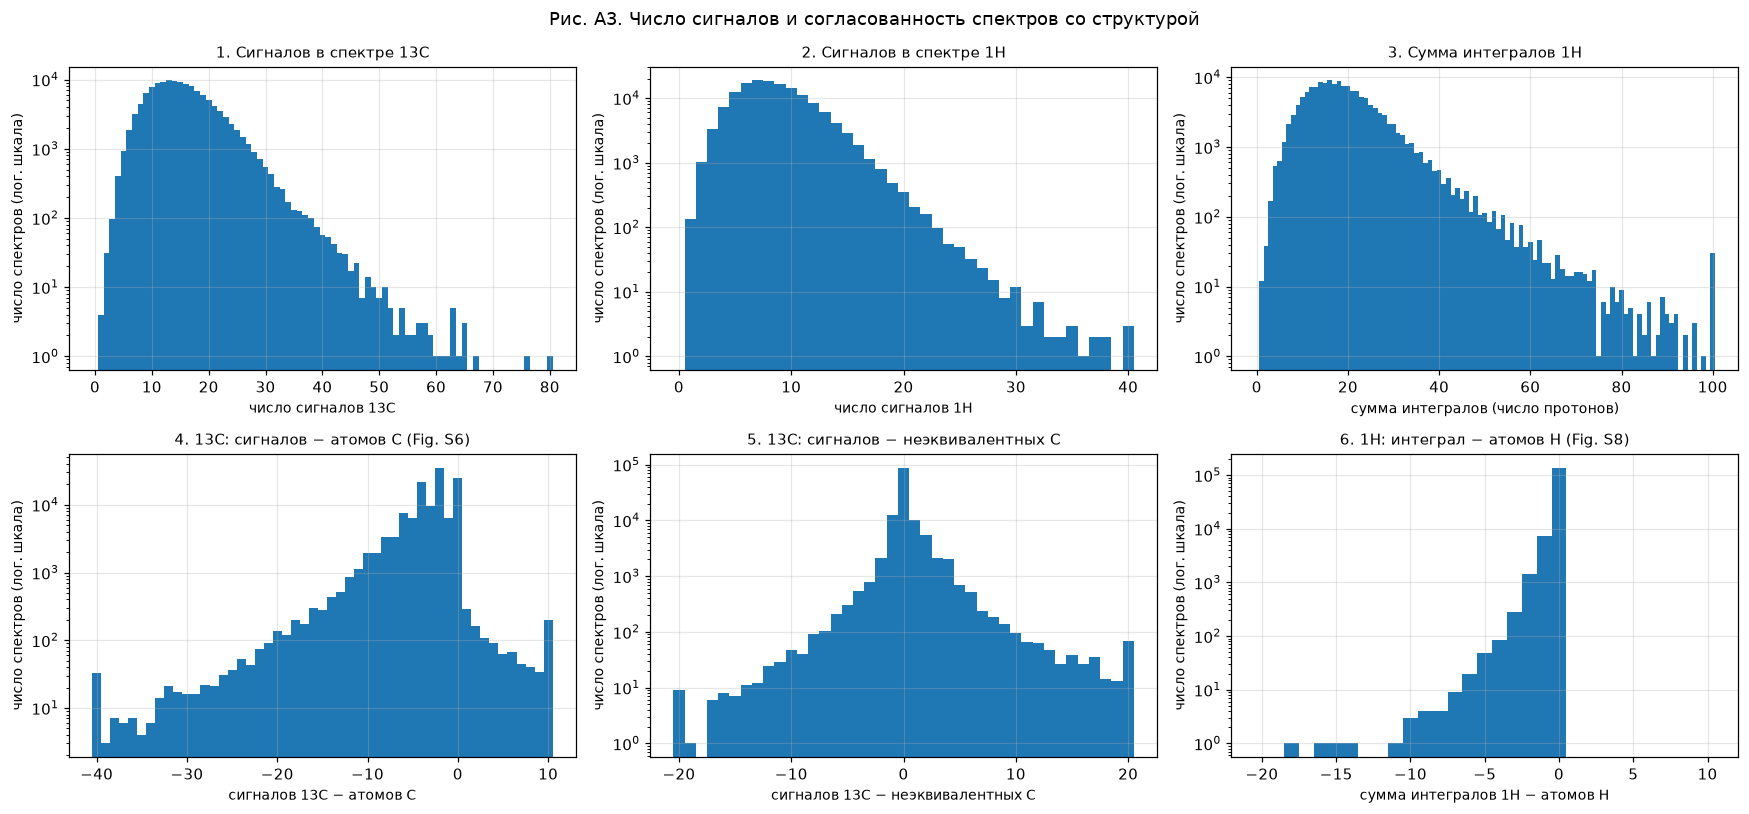

13C: спектров, где сигналов больше, чем атомов C: 0.86%; сигналов ровно столько, сколько неэквивалентных C: 69.34%
1H: спектров с суммой интегралов в допустимом диапазоне [nH − обменные H, nH]: 99.60%
диапазон химических сдвигов 13C: -48.8 … 286.9 м.д.; 1H: -4.84 … 19.16 м.д.


In [7]:
sp = spectra.join(descriptors[["n_carbon", "n_unique_carbon", "n_hydrogen", "n_exchangeable_h"]], on="smiles")
c, h = sp[sp.spectrum_type == "C_NMR"], sp[sp.spectrum_type == "H_NMR"]
c_dev = c["n_signals"] - c["n_carbon"]
c_dev_sym = c["n_signals"] - c["n_unique_carbon"]
h_dev = h["integral"] - h["n_hydrogen"]

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, (title, xlabel, data, rng) in zip(axes.flat, [
    ("1. Сигналов в спектре 13C", "число сигналов 13C", c["n_signals"], (0, 80)),
    ("2. Сигналов в спектре 1H", "число сигналов 1H", h["n_signals"], (0, 40)),
    ("3. Сумма интегралов 1H", "сумма интегралов (число протонов)", h["integral"], (0, 100)),
    ("4. 13C: сигналов − атомов C (Fig. S6)", "сигналов 13C − атомов C", c_dev, (-40, 10)),
    ("5. 13C: сигналов − неэквивалентных C", "сигналов 13C − неэквивалентных C", c_dev_sym, (-20, 20)),
    ("6. 1H: интеграл − атомов H (Fig. S8)", "сумма интегралов 1H − атомов H", h_dev, (-20, 10)),
]):
    ax.hist(data.clip(*rng), bins=np.arange(rng[0], rng[1] + 2) - 0.5)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("число спектров (лог. шкала)")
    ax.set_yscale("log"); ax.grid(alpha=0.3)
fig.suptitle("Рис. A3. Число сигналов и согласованность спектров со структурой")
plt.tight_layout(); plt.show()
print(f"13C: спектров, где сигналов больше, чем атомов C: {(c_dev > 0).mean():.2%}; "
      f"сигналов ровно столько, сколько неэквивалентных C: {(c_dev_sym == 0).mean():.2%}")
print(f"1H: спектров с суммой интегралов в допустимом диапазоне [nH − обменные H, nH]: {((h_dev <= 0.5) & (h_dev >= -h['n_exchangeable_h'] - 0.5)).mean():.2%}")
print(f"диапазон химических сдвигов 13C: {c['shift_min'].min():.1f} … {c['shift_max'].max():.1f} м.д.; 1H: {h['shift_min'].min():.2f} … {h['shift_max'].max():.2f} м.д.")

### Рис. A4. Мультиплетности и константы J

1. **Мультиплетности** (аналог Fig. S1): сколько раз каждая метка (s, d, t, dd, m, …) встречается среди всех пиков теста. Метки исходные, до сведения к словарю модели; показаны 25 самых частых, остальные собраны в «прочие». Ось Y — число пиков, логарифмическая шкала.
2. **Констант J на пик:** ось X — сколько констант указано у пика (0 — не указано, например синглет или «m»), ось Y — число пиков, логарифмическая шкала. Модель использует до 4 констант.
3. **Значения J:** ось X — константа в Гц (показаны значения < 60 Гц), ось Y — число констант, логарифмическая шкала. В 13C большие J — это обычно расщепление на фторе или фосфоре.

Синий цвет — пики 13C, красный — 1H.

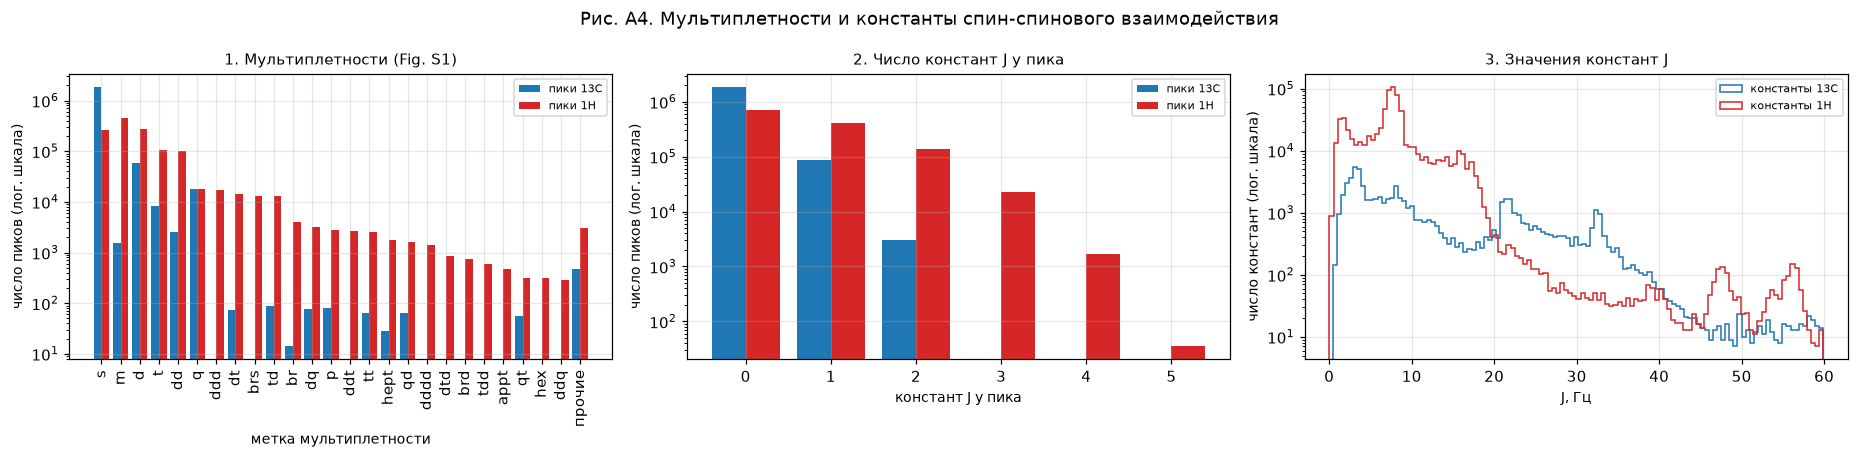

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for spectrum_type, color, offset, name in (("C_NMR", "#1f77b4", -0.2, "13C"), ("H_NMR", "#d62728", 0.2, "1H")):
    sub = sp[sp.spectrum_type == spectrum_type]
    nj =pd.Series(Counter(n for ns in sub["n_couplings"] for n in ns)).sort_index()
    axes[1].bar(nj.index + offset, nj.values, width=0.4, color=color, label=f"пики {name}")
    js = np.array([j for js in sub["couplings"] for j in js])
    axes[2].hist(js[js < 60], bins=120, histtype="step", color=color, label=f"константы {name}")
# Мультиплетности: 25 самых частых меток (по 1H и 13C вместе), остальные — в столбце «прочие»
h_counts = pd.Series(Counter(m for ms in sp[sp.spectrum_type == "H_NMR"]["multiplicities"] for m in ms))
c_counts = pd.Series(Counter(m for ms in sp[sp.spectrum_type == "C_NMR"]["multiplicities"] for m in ms))
top = (h_counts.add(c_counts, fill_value=0)).sort_values(ascending=False).index[:25]
def top_counts(counts):
    return pd.concat([counts.reindex(top).fillna(0), pd.Series({"прочие": counts.drop(top, errors="ignore").sum()})])
labels = list(top) + ["прочие"]
axes[0].bar(np.arange(len(labels)) - 0.2, top_counts(c_counts).values, width=0.4, color="#1f77b4", label="пики 13C")
axes[0].bar(np.arange(len(labels)) + 0.2, top_counts(h_counts).values, width=0.4, color="#d62728", label="пики 1H")
axes[0].set_xticks(np.arange(len(labels)), labels, rotation=90)
axes[0].set_title("1. Мультиплетности (Fig. S1)"); axes[0].set_xlabel("метка мультиплетности"); axes[0].set_ylabel("число пиков (лог. шкала)")
axes[1].set_title("2. Число констант J у пика"); axes[1].set_xlabel("констант J у пика"); axes[1].set_ylabel("число пиков (лог. шкала)")
axes[2].set_title("3. Значения констант J"); axes[2].set_xlabel("J, Гц"); axes[2].set_ylabel("число констант (лог. шкала)")
for ax in axes: ax.set_yscale("log"); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle("Рис. A4. Мультиплетности и константы спин-спинового взаимодействия")
plt.tight_layout(); plt.show()

## B. Метрики по модальностям (аналог Fig. 3A, Tables S5, S6)

### Таблица B1. Сводные метрики
Строки — запуск и модальность; `Overall` — все примеры вместе. Значения — доли от 0 до 1 (0.4783 = 47.83%).

| столбец | что значит |
|---|---|
| `count` | число примеров (пар спектров) |
| `top1_valid` | жадный ответ — валидный SMILES (RDKit его разбирает) |
| `top1_exact` | жадный ответ совпал с правильным, включая стереохимию |
| `top1_topo` | жадный ответ совпал без учёта стереохимии |
| `topn_valid` | среди кандидатов из сэмплов есть хотя бы один валидный |
| `topn_exact` | правильная структура есть среди кандидатов top-10 |
| `topn_topo` | правильный скелет есть среди кандидатов top-10 |
| `first_exact` | верен кандидат с наибольшим log-likelihood из сэмплов (то есть сэмплирование с переранжированием как top-1) |
| `topn_unique` | среднее число разных структур среди 10 сэмплов: 1 — модель уверена, 10 — сильно сомневается |

Все SMILES перед сравнением заново канонизированы RDKit, поэтому числа могут немного отличаться от того, что печатают сами скрипты оценки.

In [9]:
frames = [L.load_run(name, paths.get("top1"), paths.get("topn"), top_n=TOP_N) for name, paths in RUNS.items()]
df = pd.concat(frames, ignore_index=True)
if EXCLUDE_FLAGGED:
    df = df[~df["true_smiles"].isin(flagged)]
df = L.add_descriptors(df, L.descriptor_table(df["true_smiles"]))
if "first_pred" in df:
    df = L.add_token_lengths(df, TOKENIZER_PATH)
df["flagged"] = df["true_smiles"].isin(flagged)
display(L.summary_table(df))

count  top1_valid  top1_exact  top1_topo  topn_valid  topn_exact  topn_topo  first_exact  topn_unique
run                modality                                                                                                        
with J (epoch 199) Only C      7948      0.9879      0.1544     0.1950      1.0000      0.2648     0.3153       0.1803       7.6731
                   Only H     27766      0.9881      0.2383     0.2842      0.9999      0.3823     0.4252       0.2682       6.6585
                   Both      119987      0.9881      0.4783     0.5712      0.9999      0.6335     0.6918       0.5011       3.8984
                   Overall   155701      0.9881      0.4190     0.5008      0.9999      0.5699     0.6251       0.4432       4.5833

### Таблица B2. Парное сравнение запусков (тест McNemar)
Запуски сравниваются на одних и тех же примерах. Нужно минимум два запуска в `RUNS`.

- `a`, `b` — сравниваемые запуски; `metric` — какая метрика; `n` — число примеров.
- `acc_a`, `acc_b` — точность каждого; `diff` = acc_a − acc_b.
- `only_a` — сколько примеров решил только `a`; `only_b` — только `b`. Тест смотрит только на эти несовпадения: если они примерно равны, разницы нет.
- `p_value` — вероятность получить такую или большую разницу случайно; меньше 0.05 обычно считают значимой разницей.

In [10]:
runs = list(RUNS)
rows = []
for i, a in enumerate(runs):
    for b in runs[i + 1:]:
        A = df[df.run == a].set_index("case"); B = df[df.run == b].set_index("case")
        for metric in [m for m in ("top1_exact", "top1_topo", "topn_exact", "first_exact") if m in A and m in B]:
            for modality in (*L.MODALITIES, "Overall"):
                idx = A.index if modality == "Overall" else A.index[A.modality == modality]
                rows.append({"a": a, "b": b, "metric": metric, "modality": modality, "n": len(idx),
                             **L.mcnemar(A.loc[idx, metric].astype(bool), B.loc[idx, metric].astype(bool))})
display(pd.DataFrame(rows)) if rows else print("в RUNS один запуск — сравнивать не с чем")

в RUNS один запуск — сравнивать не с чем


### Таблицы B3, B4. «Идеальное» подмножество и молекулы, похожие на train/val

**B3** — точность на «идеальном» подмножестве из статьи (`ideal = True`) и на остальных примерах. Идеальный пример — это:
- ≤ 30 тяжёлых атомов;
- сигналов 13C не больше, чем атомов C;
- интеграл 1H в допустимом диапазоне;
- только частые элементы (C, H, N, O, S, P, F, Cl, Br, I, Si, B);
- не больше одного стереоцентра;
- одна частица в SMILES.

**B4** — точность отдельно для молекул, помеченных `check_leakage.py` (`flagged = True`), и для остальных. Если у помеченных точность заметно выше, то похожие пары между сплитами модели помогают.

Столбцы — те же метрики, что в B1; `count` — число примеров в строке.

In [11]:
metrics = [m for m in ("top1_exact", "top1_topo", "topn_exact", "first_exact") if m in df]
display(df.groupby(["run", "ideal"])[metrics].mean().assign(count=df.groupby(["run", "ideal"]).size()))
display(df.groupby(["run", "flagged"])[metrics].mean().assign(count=df.groupby(["run", "flagged"]).size()))

top1_exact  top1_topo  topn_exact  first_exact   count
run                ideal                                                        
with J (epoch 199) False      0.2043     0.3189      0.3442       0.2211   44261
                   True       0.5042     0.5731      0.6595       0.5314  111440

top1_exact  top1_topo  topn_exact  first_exact   count
run                flagged                                                        
with J (epoch 199) False        0.4142     0.4965      0.5655       0.4382  151374
                   True         0.5870     0.6517      0.7224       0.6194    4327

## C. Точность в зависимости от сложности молекулы и спектра

**Как читать графики этой части.** Каждый рисунок — три панели с одинаковой осью X:
1. точное совпадение жадного ответа (top-1);
2. совпадение жадного ответа без стереохимии;
3. правильный ответ среди кандидатов top-10.

- **Ось X** — свойство молекулы или спектра (подписано под осью).
- **Ось Y** — доля правильно решённых примеров с этим значением свойства (0.5 = 50%).
- **Цвет** — модальность: синий `Only C`, красный `Only H`, зелёный `Both`. **Стиль линии** — запуск.
- **Полоса** — 95% доверительный интервал. Широкая полоса означает, что примеров мало и значению стоит доверять меньше.
- Точки, где примеров меньше `MIN_COUNT`, не рисуются, поэтому у редких модальностей линии короче.

In [12]:
TARGETS = [t for t in ("top1_exact", "top1_topo", "topn_exact") if t in df]
PANEL = {"top1_exact": "точно, top-1", "top1_topo": "без стереохимии, top-1", "topn_exact": "точно, top-10"}

def grid(x, data=None, title="", rotate=False):
    data = df if data is None else data
    fig, axes = plt.subplots(1, len(TARGETS), figsize=(5.8 * len(TARGETS), 4.2), sharey=True)
    for ax, t in zip(np.atleast_1d(axes), TARGETS):
        L.plot_rate(data, t, x, ax, min_count=MIN_COUNT, title=PANEL[t], ylabel="доля правильных ответов")
        if rotate: ax.tick_params(axis="x", rotation=60)
    np.atleast_1d(axes)[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", title=LEGEND_TITLE)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

### Рис. C1–C5. Размер и состав молекулы
- **C1** — по числу атомов углерода (аналог Fig. 3B, S14);
- **C2** — по числу тяжёлых атомов;
- **C3** — по молекулярной массе: интервалы `a–b` в Да (больше a, не больше b);
- **C4** — по числу гетероатомов;
- **C5** — по числу циклов.

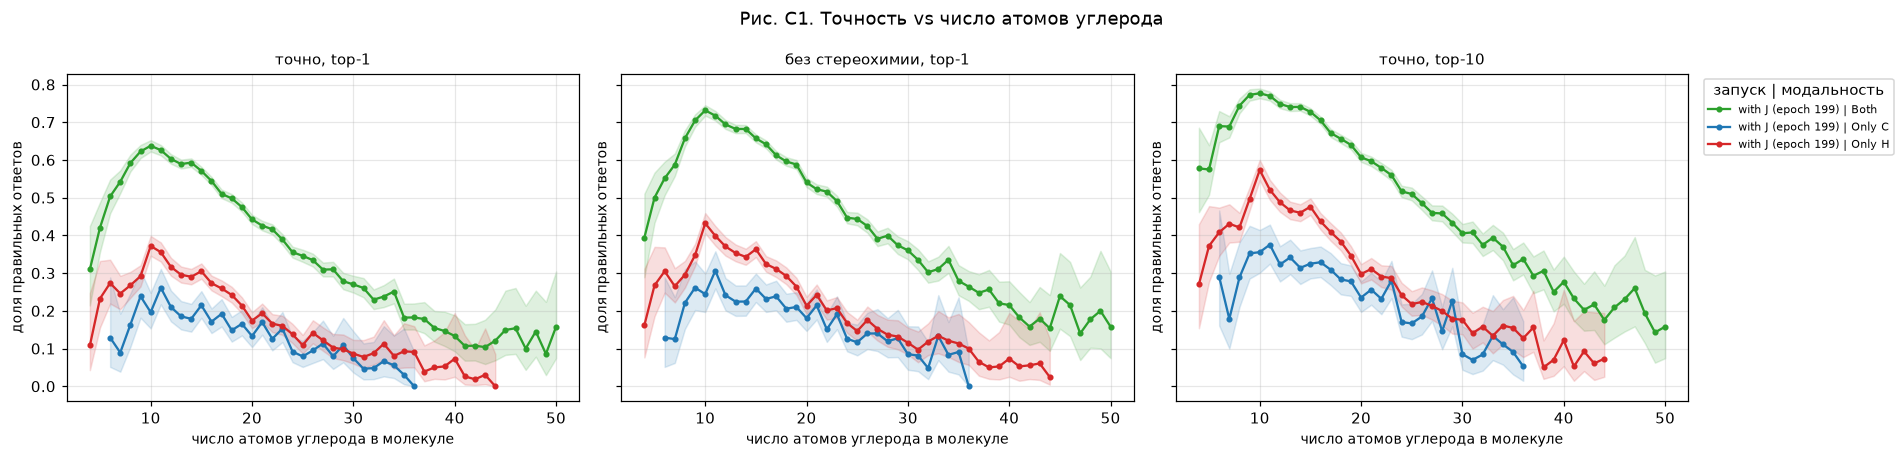

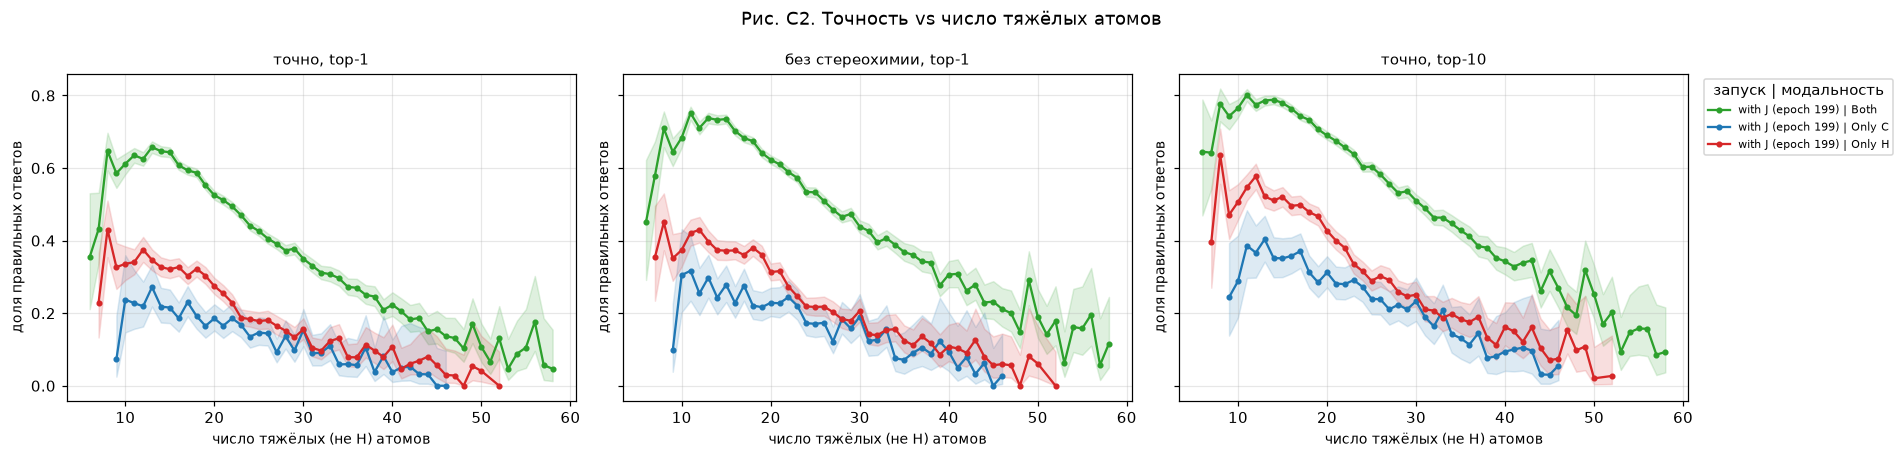

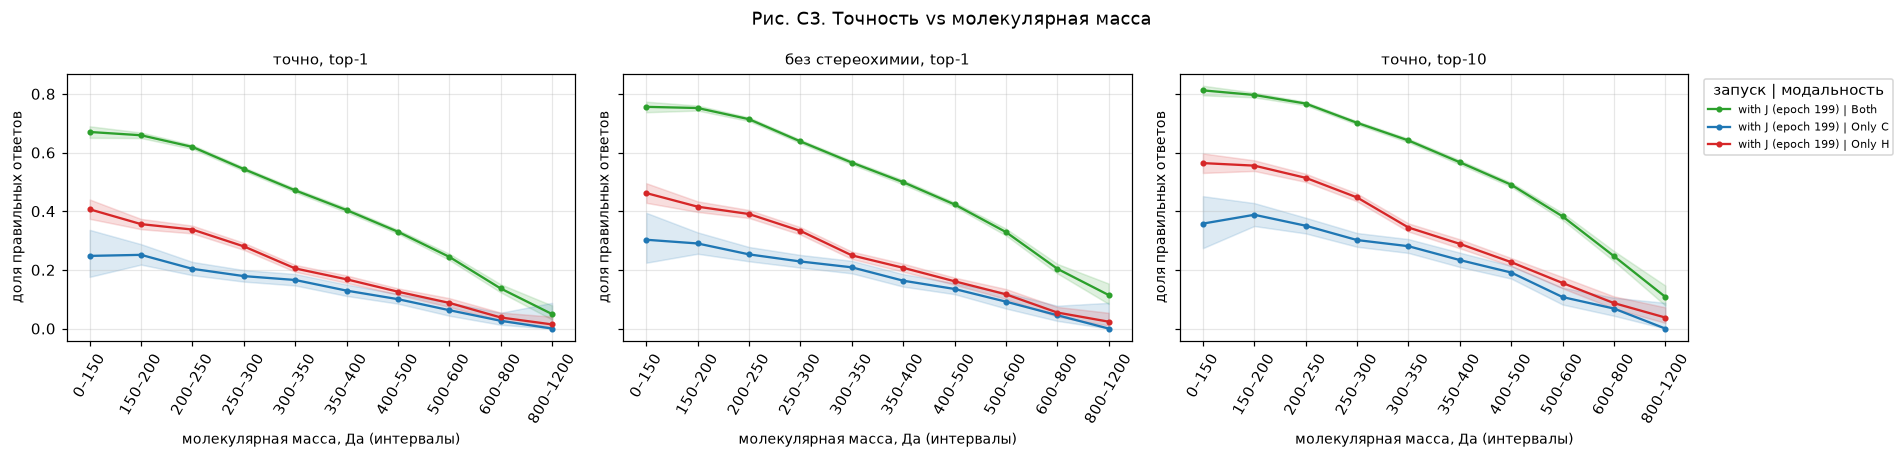

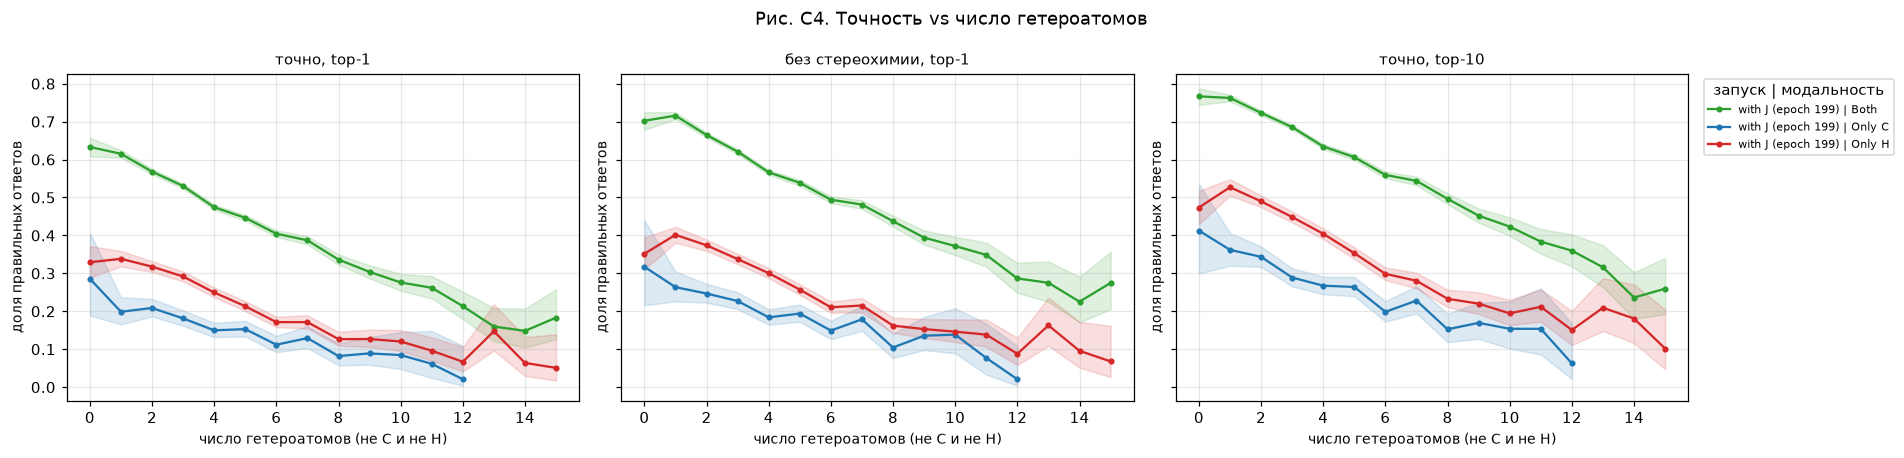

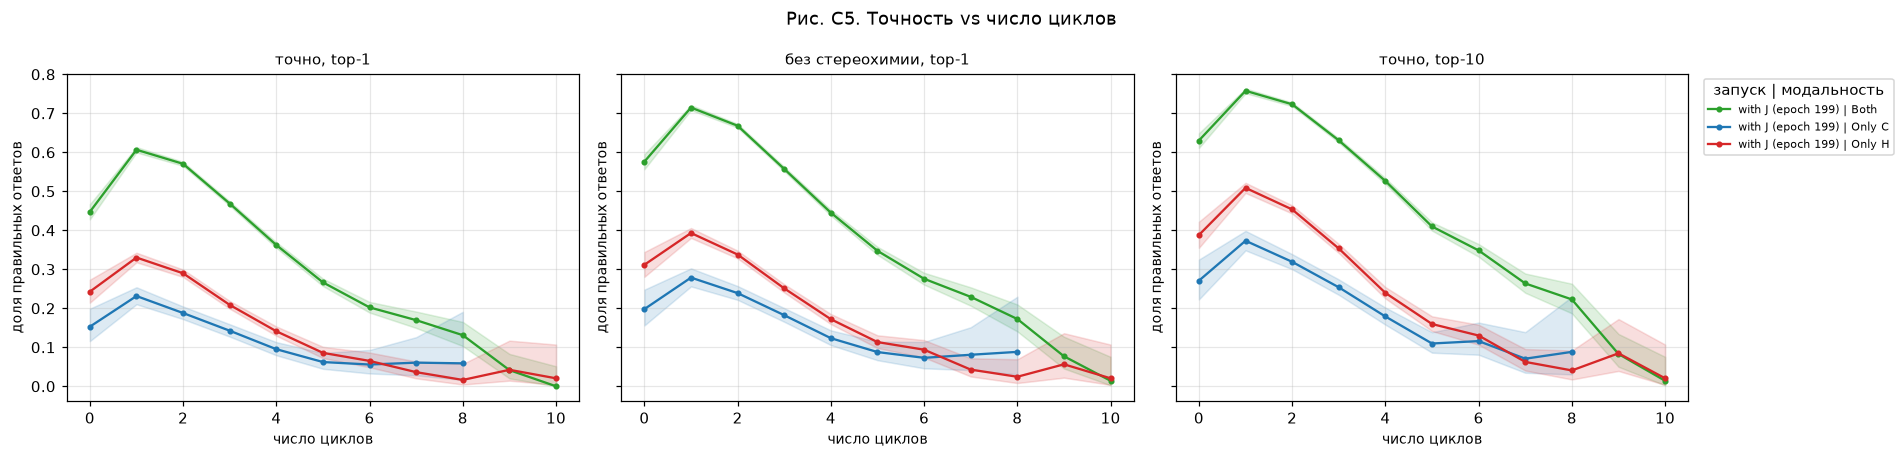

In [13]:
grid("n_carbon", df[df.n_carbon <= 60], "Рис. C1. Точность vs число атомов углерода")
grid("heavy_atoms", df[df.heavy_atoms <= 70], "Рис. C2. Точность vs число тяжёлых атомов")
MW_EDGES = [0, 150, 200, 250, 300, 350, 400, 500, 600, 800, 1200, 1e5]
df["mw_bin"] = pd.cut(df["mol_weight"], MW_EDGES, labels=[f"{a:g}–{b:g}" for a, b in zip(MW_EDGES[:-2], MW_EDGES[1:-1])] + [">1200"])
grid("mw_bin", title="Рис. C3. Точность vs молекулярная масса", rotate=True)
grid("n_heteroatoms", df[df.n_heteroatoms <= 15], "Рис. C4. Точность vs число гетероатомов")
grid("n_rings", df[df.n_rings <= 10], "Рис. C5. Точность vs число циклов")

### Элементный состав (аналог Fig. 3C)

- **Таблица C1** — точное совпадение top-1 по категориям молекул. Строки — категории из A3 (пересекаются); столбцы — запуск и модальность.
- **Таблица C2** — число примеров в каждой ячейке C1. Если примеров меньше ~100, точность сильно шумит.
- **Рис. C6** — та же точность для модальности `Both` в виде столбцов. Ось X — категория, ось Y — доля точных совпадений top-1, пунктир — средняя точность по всем примерам `Both`.

Таблица C1. Доля точных совпадений top-1 по категориям


run              with J (epoch 199)                      
modality                       Both Only C Only H Overall
category                                                 
C,H only                     0.6331 0.2857 0.3293  0.5494
C,H,O only                   0.5121 0.1617 0.3162  0.4587
C,H,N,O only                 0.4822 0.1567 0.2383  0.4265
contains N                   0.4525 0.1446 0.2024  0.3941
contains O                   0.4696 0.1518 0.2407  0.4131
contains S                   0.4427 0.1256 0.1889  0.3870
contains P                   0.4652 0.2336 0.2136  0.3867
contains F                   0.5288 0.2136 0.2174  0.4309
contains Cl                  0.4330 0.1478 0.1765  0.3796
contains Br                  0.4316 0.1192 0.1831  0.3742
contains I                   0.4398 0.1080 0.1726  0.3678
contains Si                  0.4081 0.1079 0.2400  0.3616
contains B                   0.4790 0.1078 0.3473  0.4309
contains Se                  0.3755 0.0980 0.1032  0.3312
contains halogen             0.4777 0.1608 0.2065  0.4058
rare element                 0.1455 0.1429 0.0732  0.1266
metal                        0.1455 0.1429 0.0732  0.1266
charged                      0.3352 0.1073 0.1265  0.2815
multiple species             0.1734 0.0000 0.0486  0.1240

Таблица C2. Число примеров в каждой ячейке


run              with J (epoch 199)                                 
modality                       Both    Only C     Only H     Overall
category                                                            
C,H only                  1491.0000   63.0000   492.0000   2046.0000
C,H,O only               17626.0000 1311.0000  3871.0000  22808.0000
C,H,N,O only             36536.0000 2585.0000  7095.0000  46216.0000
contains N               76748.0000 5132.0000 16705.0000  98585.0000
contains O              102306.0000 6957.0000 22963.0000 132226.0000
contains S               25308.0000 1489.0000  5150.0000  31947.0000
contains P                2747.0000  214.0000  1058.0000   4019.0000
contains F               18920.0000  974.0000  7687.0000  27581.0000
contains Cl              12533.0000  758.0000  2431.0000  15722.0000
contains Br               9807.0000  671.0000  2054.0000  12532.0000
contains I                2692.0000  176.0000   759.0000   3627.0000
contains Si               5756.0000  482.0000  1196.0000   7434.0000
contains B                2453.0000  167.0000   766.0000   3386.0000
contains Se               1068.0000   51.0000   155.0000   1274.0000
contains halogen         39969.0000 2339.0000 11532.0000  53840.0000
rare element               110.0000    7.0000    41.0000    158.0000
metal                      110.0000    7.0000    41.0000    158.0000
charged                   7429.0000  550.0000  1952.0000   9931.0000
multiple species           323.0000   41.0000   144.0000    508.0000

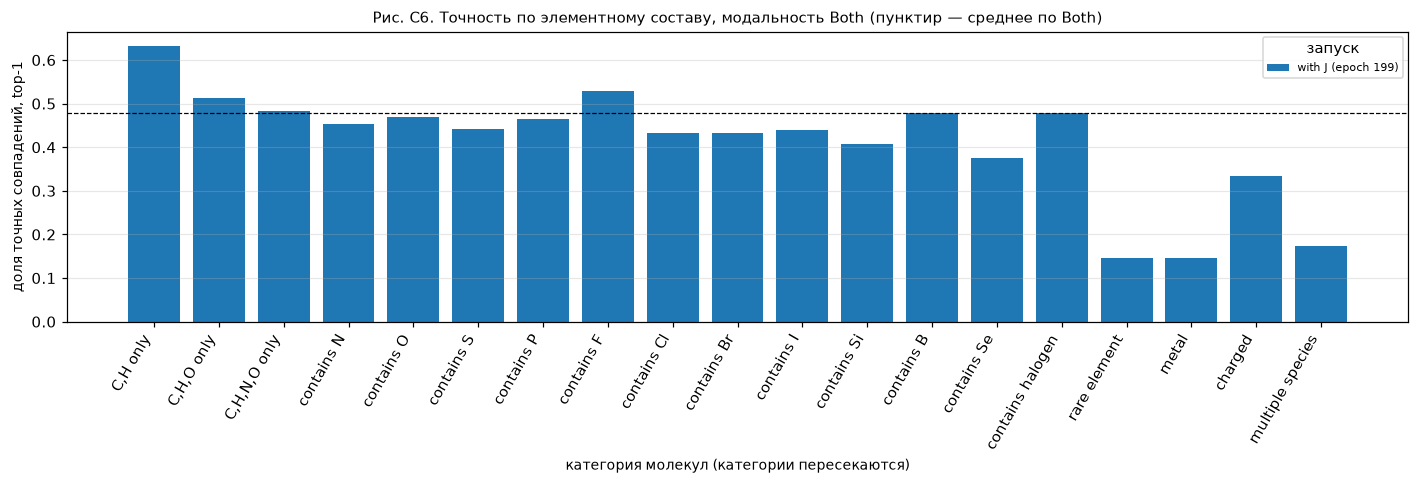

In [14]:
cats = L.element_categories(df)
rows = []
for name, mask in cats.items():
    sub = df[mask.fillna(False).astype(bool)]
    for (run, modality), g in pd.concat([sub, sub.assign(modality="Overall")]).groupby(["run", "modality"]):
        rows.append({"category": name, "run": run, "modality": modality, "count": len(g), **{t: g[t].mean() for t in TARGETS}})
cat_table = pd.DataFrame(rows)
print("Таблица C1. Доля точных совпадений top-1 по категориям")
display(cat_table.pivot_table(index="category", columns=["run", "modality"], values=TARGETS[0]).reindex(list(cats)))
print("Таблица C2. Число примеров в каждой ячейке")
display(cat_table.pivot_table(index="category", columns=["run", "modality"], values="count").reindex(list(cats)))

both = cat_table[cat_table.modality == "Both"]
fig, ax = plt.subplots(figsize=(13, 4.5))
width = 0.8 / max(both.run.nunique(), 1)
for i, (run, g) in enumerate(both.groupby("run", sort=False)):
    g = g.set_index("category").reindex(list(cats))
    ax.bar(np.arange(len(g)) + i * width, g[TARGETS[0]], width=width, label=run)
    ax.axhline(df[(df.run == run) & (df.modality == "Both")][TARGETS[0]].mean(), ls="--", lw=0.8, color="k")
ax.set_xticks(np.arange(len(cats)) + width * (both.run.nunique() - 1) / 2, list(cats), rotation=60, ha="right")
ax.set_xlabel("категория молекул (категории пересекаются)"); ax.set_ylabel("доля точных совпадений, top-1")
ax.set_title("Рис. C6. Точность по элементному составу, модальность Both (пунктир — среднее по Both)")
ax.legend(title="запуск"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

### Рис. C7, C8. Стереохимия (аналог Fig. 3D)

Берутся только примеры, где скелет предсказан верно (совпадение без стереохимии). Для них считается доля, где и стереохимия верна.

- **Ось X** — число стереоцентров в правильной молекуле.
- **Ось Y** — доля верной стереохимии среди верных скелетов.
- **C7** — для жадного top-1; **C8** — для top-10: верная стереоформа найдена среди кандидатов, если найден верный скелет.

При 0 стереоцентров доля почти 1: там стереохимия может быть только у двойных связей (E/Z).

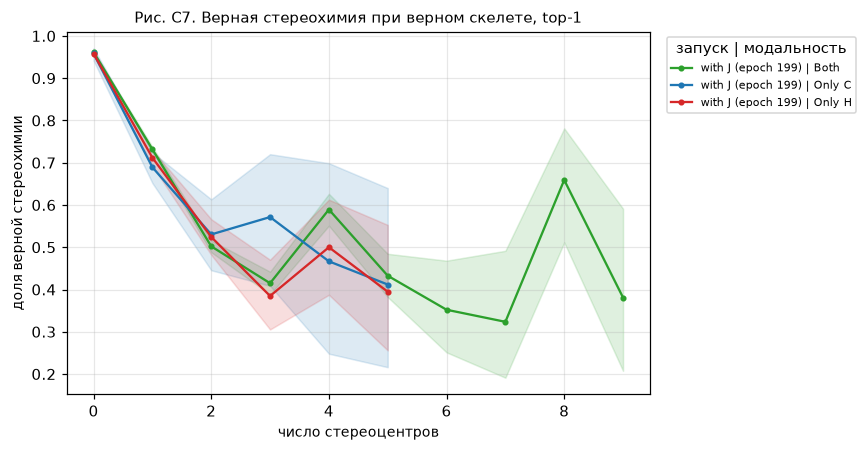

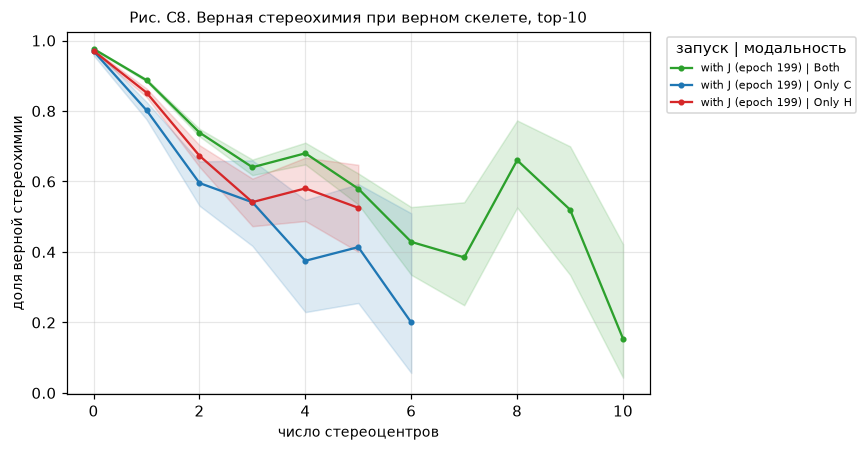

In [15]:
for fig_no, (exact, topo, name) in zip(("C7", "C8"), (("top1_exact", "top1_topo", "top-1"), ("topn_exact", "topn_topo", "top-10"))):
    if exact not in df: continue
    sub = df[df[topo]]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    L.plot_rate(sub[sub.n_stereocenters <= 12], exact, "n_stereocenters", ax, min_count=MIN_COUNT // 3,
                title=f"Рис. {fig_no}. Верная стереохимия при верном скелете, {name}",
                ylabel="доля верной стереохимии")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title=LEGEND_TITLE); plt.tight_layout(); plt.show()

### Рис. C9–C14. Согласованность спектра со структурой (аналоги Fig. S3, S6, S8, S13, S15)

Насколько спектр соответствует молекуле, и как это влияет на точность.

- **C9** — ось X: сигналов 13C − атомов C (как в статье). 0 — сигналов столько же, сколько атомов углерода; −5 — на 5 сигналов меньше (совпавшие сдвиги или симметрия).
- **C10** — ось X: сигналов 13C − неэквивалентных атомов C (с учётом симметрии). 0 — полностью согласованный спектр.
- **C11** — ось X: сумма интегралов 1H − атомов H, округлено. 0 — интегралы точно сходятся, отрицательные значения — «потерянные» протоны (обычно OH и NH). Значения ниже −10 и выше 6 собраны в крайние точки.
- **C12** — ось X: сумма интегралов 1H (интервалы по 5 протонов, начало интервала; всё ≥ 100 собрано в 100). Это размер молекулы с точки зрения протонов (Fig. S3).
- **C13** — ось X: число сигналов в спектре 13C (аналог Fig. 3B статьи).
- **C14** — ось X: число сигналов в спектре 1H.

Панели и цвета — как в начале части C. Для признаков 13C нет линии `Only H` (там нет спектра 13C), и наоборот.

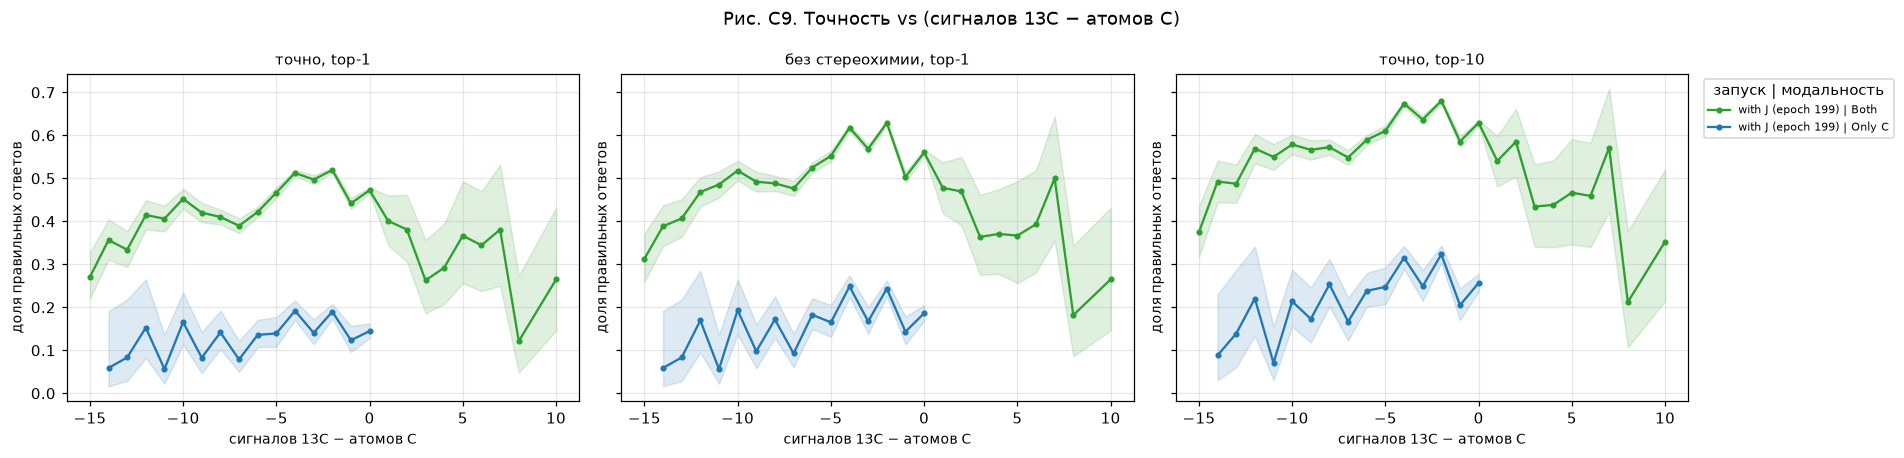

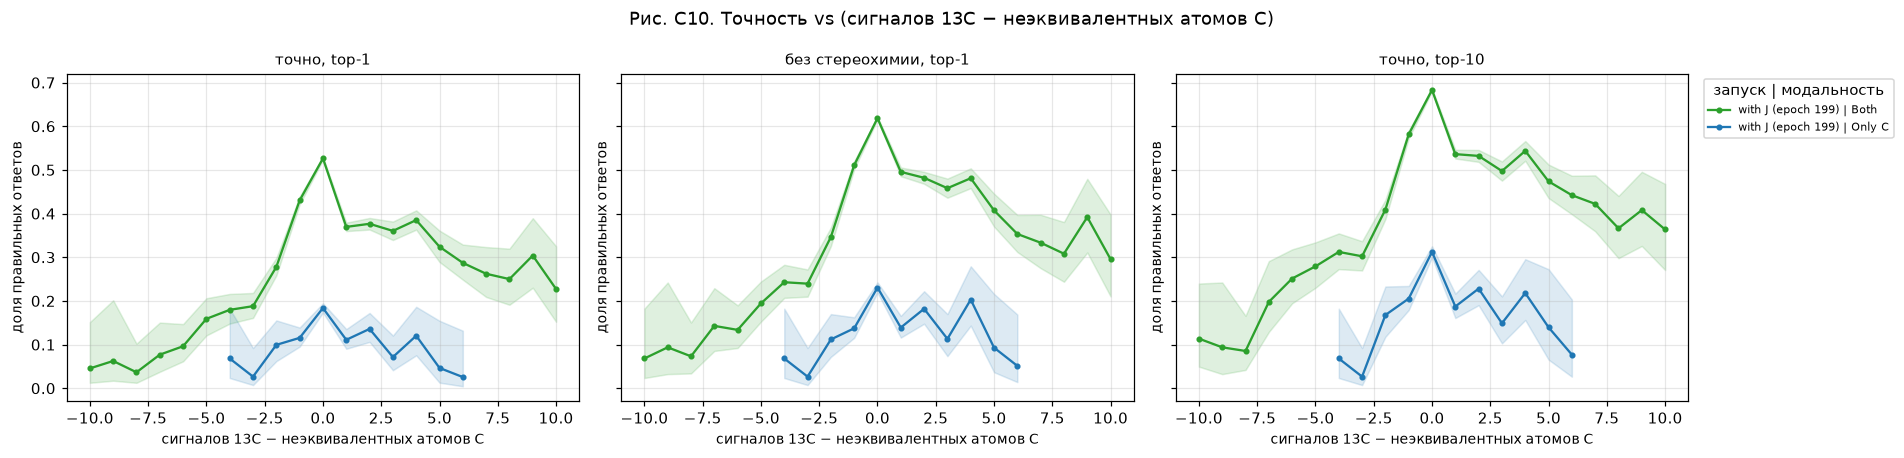

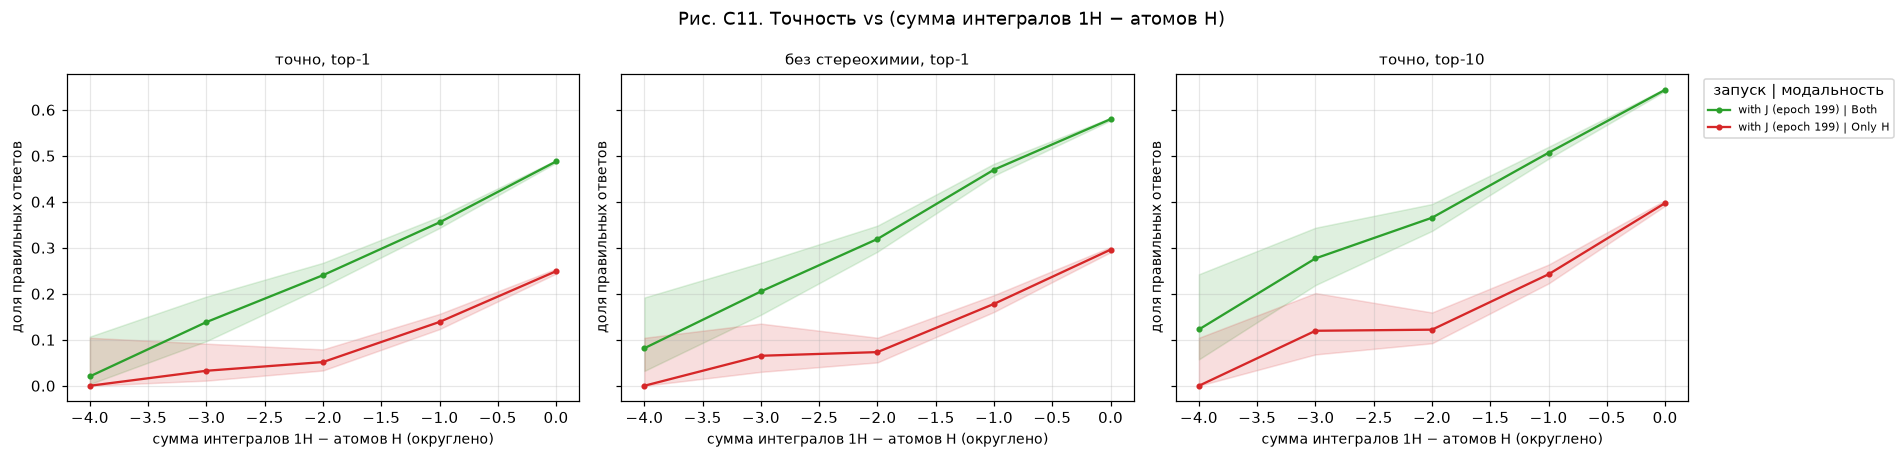

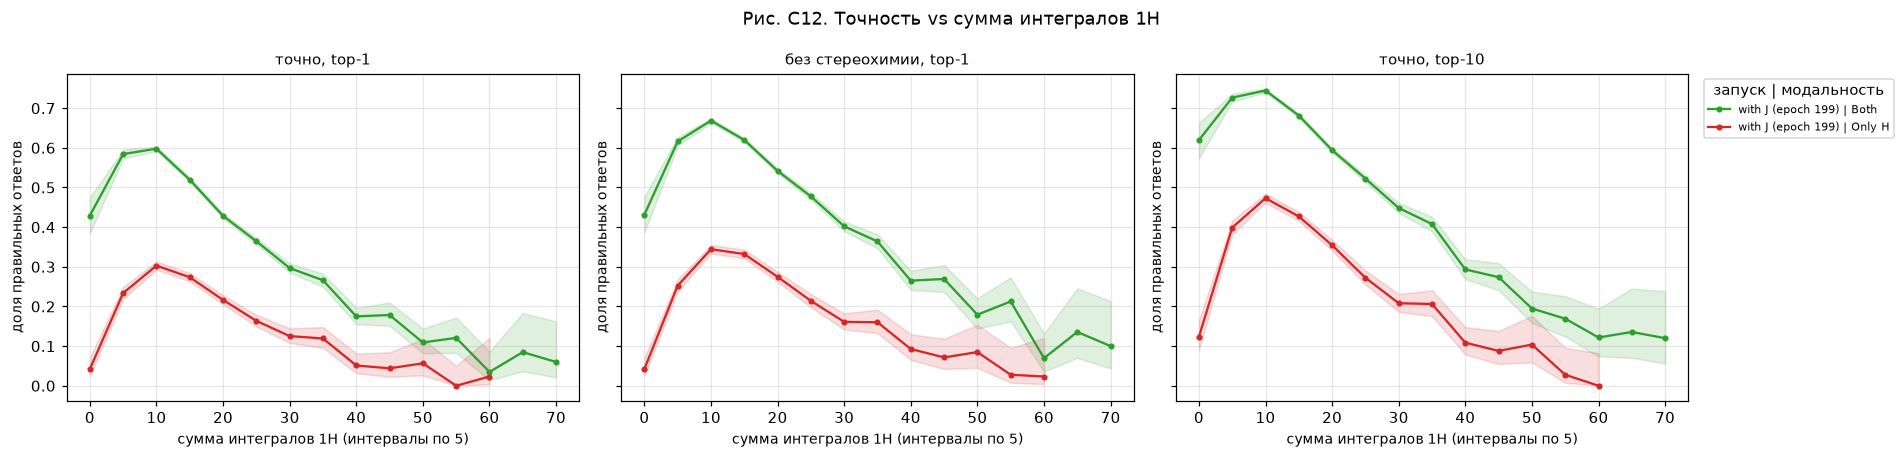

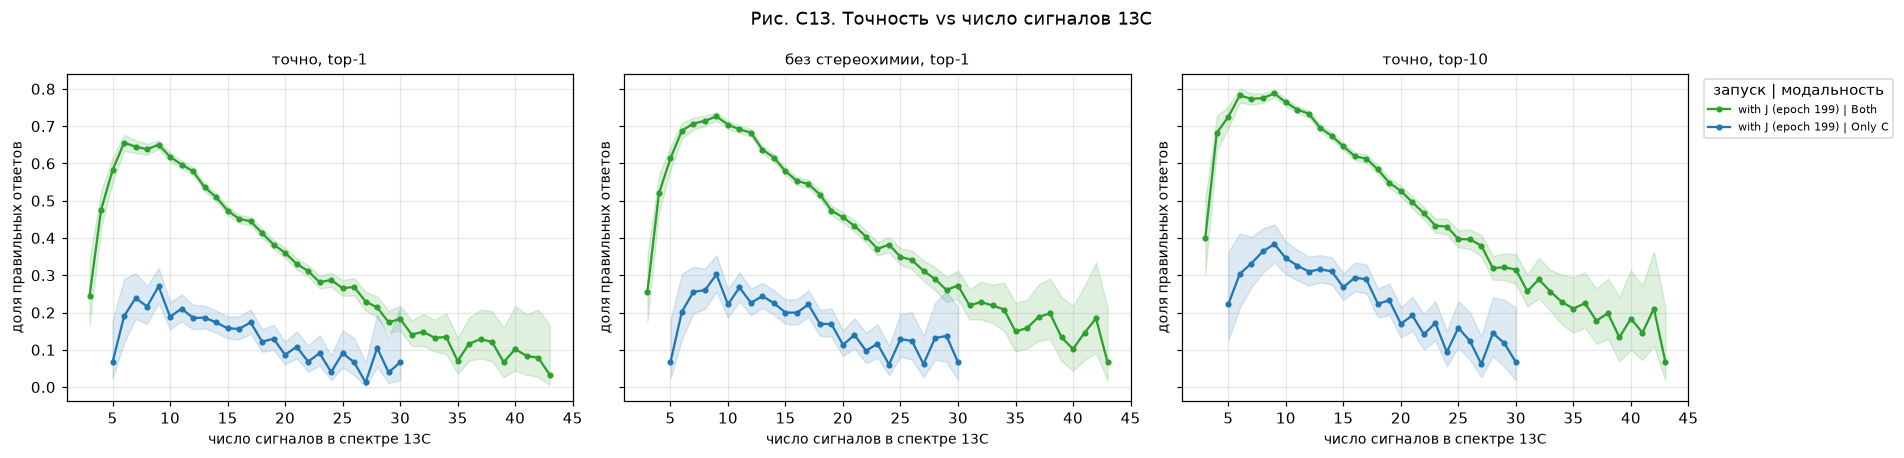

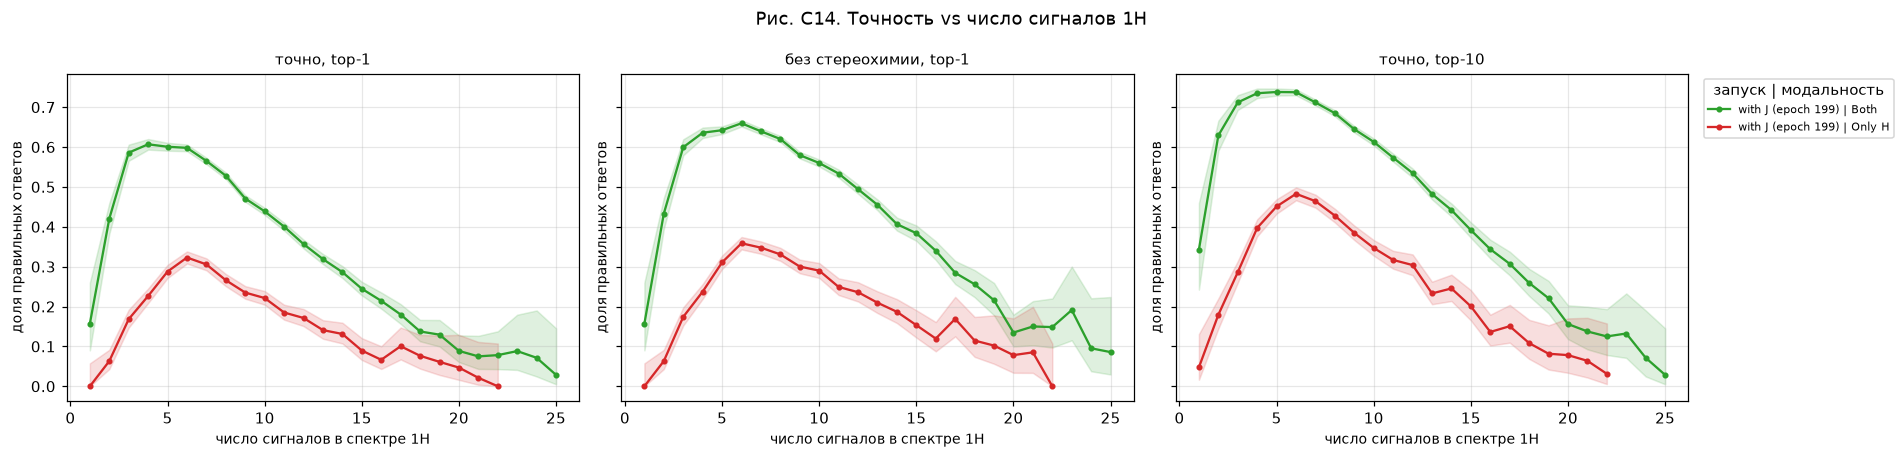

In [16]:
grid("c_signal_dev", df[df.c_signal_dev.between(-15, 10)], "Рис. C9. Точность vs (сигналов 13C − атомов C)")
grid("c_signal_dev_sym", df[df.c_signal_dev_sym.between(-10, 10)], "Рис. C10. Точность vs (сигналов 13C − неэквивалентных атомов C)")
df["h_dev_bin"] = df["h_integral_dev"].round().clip(-10, 6)
grid("h_dev_bin", df[df.h_dev_bin.notna()], "Рис. C11. Точность vs (сумма интегралов 1H − атомов H)")
df["h_integral_bin"] = (df["h_integral"] // 5 * 5).clip(upper=100)
grid("h_integral_bin", df[df.h_integral_bin.notna()], "Рис. C12. Точность vs сумма интегралов 1H")
grid("c_signals", df[df.c_signals <= 60], "Рис. C13. Точность vs число сигналов 13C")
grid("h_signals", df[df.h_signals <= 35], "Рис. C14. Точность vs число сигналов 1H")

## D. Насколько неверные ответы похожи на правильные (аналог Fig. S11)

Для каждого неверного жадного ответа считается **сходство Танимото** с правильной структурой: доля общих фрагментов в отпечатках Morgan (радиус 4, 4096 бит, как в статье).
- 1 — отпечатки совпадают: обычно стереоизомер или очень близкий изомер.
- 0 — общих фрагментов нет.

**Таблица D1** — описательная статистика сходства по модальностям: `count` — число неверных ответов, `mean` — среднее, `50%` — медиана и т. д.

**Рис. D1:**
- **Ось X** — сходство Танимото.
- **Ось Y** — плотность: гистограмма нормирована, площадь под каждой кривой равна 1, чтобы модальности разного размера можно было сравнивать.
- В легенде указана медиана. Чем правее масса распределения, тем ближе ошибки к правильному ответу.

Таблица D1. Сходство Танимото неверных ответов с правильными


count   mean    std    min    25%    50%    75%    max
run                modality                                                            
with J (epoch 199) Both     61168.0000 0.4763 0.2959 0.0000 0.2424 0.3818 0.6456 1.0000
                   Only C    6625.0000 0.2961 0.2251 0.0000 0.1441 0.2254 0.3667 1.0000
                   Only H   20818.0000 0.3260 0.2348 0.0000 0.1636 0.2533 0.4085 1.0000

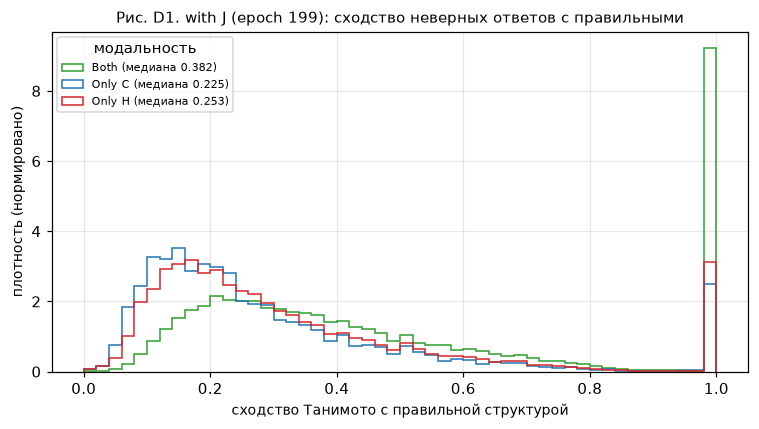

In [17]:
pred_col = "top1_pred" if "top1_pred" in df else "first_pred"
exact_col = "top1_exact" if "top1_exact" in df else "first_exact"
wrong = df[~df[exact_col].astype(bool) & df[pred_col].notna()].copy()
wrong["tanimoto"] = [L.tanimoto(p, t) for p, t in zip(wrong[pred_col], wrong["true_smiles"])]
print("Таблица D1. Сходство Танимото неверных ответов с правильными")
display(wrong.groupby(["run", "modality"])["tanimoto"].describe())
fig, axes = plt.subplots(1, len(RUNS), figsize=(7 * len(RUNS), 4), squeeze=False)
for ax, (run, g) in zip(axes[0], wrong.groupby("run", sort=False)):
    for modality, gm in g.groupby("modality"):
        ax.hist(gm["tanimoto"].dropna(), bins=50, range=(0, 1), histtype="step", density=True,
                color=L.MODALITY_COLORS[modality], label=f"{modality} (медиана {gm['tanimoto'].median():.3f})")
    ax.set_xlabel("сходство Танимото с правильной структурой"); ax.set_ylabel("плотность (нормировано)")
    ax.set_title(f"Рис. D1. {run}: сходство неверных ответов с правильными"); ax.legend(title="модальность"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## E. Top-10: разнообразие кандидатов и ранг правильного ответа

**Рис. E1, левая панель — кривая top-k.** Кандидаты упорядочены по log-likelihood.
- **Ось X** — k.
- **Ось Y** — доля примеров, где правильная структура среди первых k кандидатов.
- При k = 1 это точность лучшего кандидата; рост кривой показывает, сколько дают следующие кандидаты.

**Рис. E1, правая панель — сколько разных структур дали 10 сэмплов.**
- **Ось X** — число уникальных кандидатов.
- **Ось Y** — доля примеров.
- Пик на 1 — модель уверена и повторяет одну структуру, пик на 10 — каждый сэмпл разный.

**Рис. E2 — разнообразие vs сложность** (аналог Fig. S13, S14).
- **Ось Y** — среднее число уникальных кандидатов.
- **Ось X** — число атомов C (слева) или сигналов 13C − атомов C (справа).
- Чем больше, тем сильнее модель сомневается.

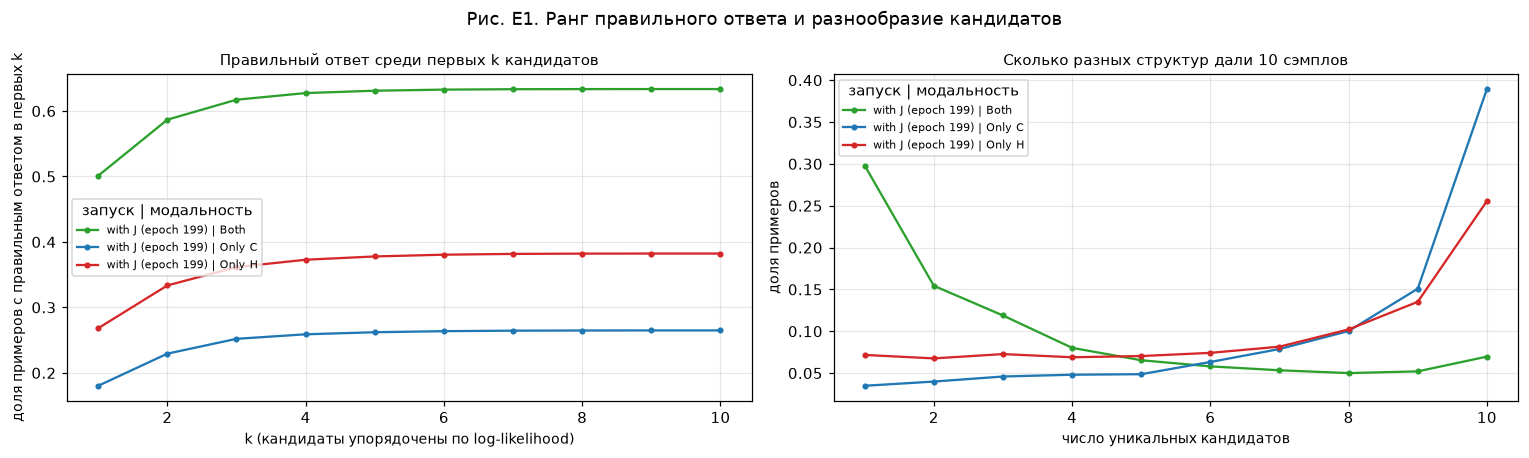

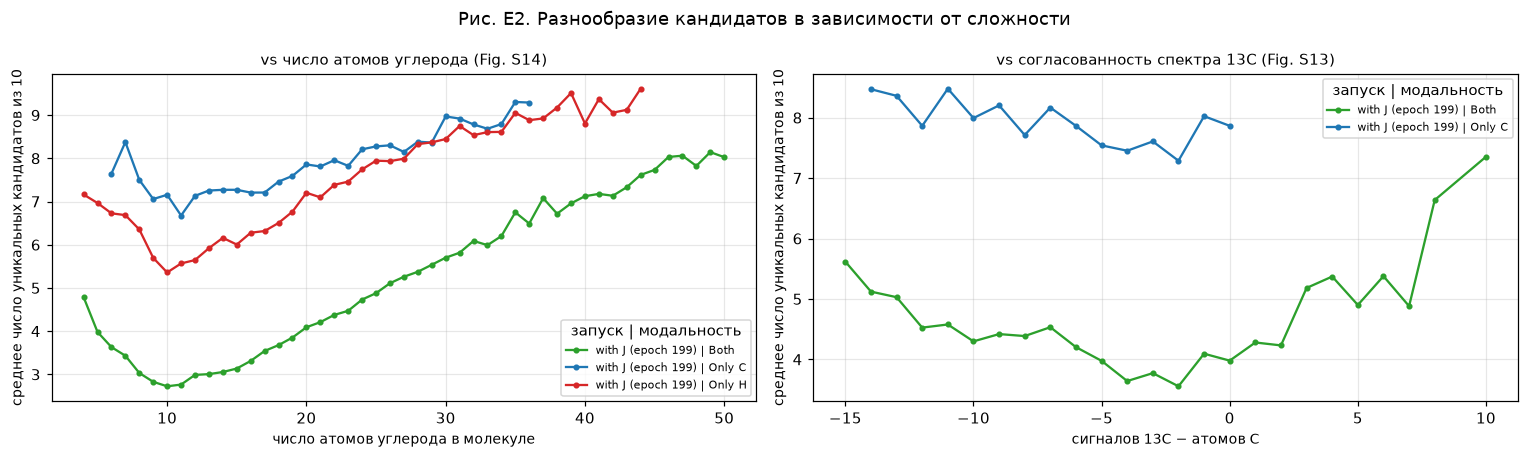

In [18]:
assert "topn_candidates" in df, "нужны выходы evaluate_top_n.py"
ks = np.arange(1, TOP_N + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for r_idx, (run, g) in enumerate(df.groupby("run", sort=False)):
    for modality, gm in g.groupby("modality"):
        style = L.RUN_STYLES[r_idx % 4]
        axes[0].plot(ks, [(gm["topn_rank"] <= k).mean() for k in ks], style, marker="o", ms=3,
                     color=L.MODALITY_COLORS[modality], label=f"{run} | {modality}")
        vc = gm["topn_unique"].clip(upper=TOP_N).value_counts(normalize=True).sort_index()
        axes[1].plot(vc.index, vc.values, style, marker="o", ms=3, color=L.MODALITY_COLORS[modality], label=f"{run} | {modality}")
axes[0].set_title("Правильный ответ среди первых k кандидатов"); axes[0].set_xlabel("k (кандидаты упорядочены по log-likelihood)")
axes[0].set_ylabel("доля примеров с правильным ответом в первых k")
axes[1].set_title("Сколько разных структур дали 10 сэмплов"); axes[1].set_xlabel("число уникальных кандидатов")
axes[1].set_ylabel("доля примеров")
for ax in axes: ax.grid(alpha=0.3); ax.legend(title=LEGEND_TITLE)
fig.suptitle("Рис. E1. Ранг правильного ответа и разнообразие кандидатов")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, x, data in ((axes[0], "n_carbon", df[df.n_carbon <= 60]), (axes[1], "c_signal_dev", df[df.c_signal_dev.between(-15, 10)])):
    for r_idx, (run, g) in enumerate(data.groupby("run", sort=False)):
        for modality, gm in g.groupby("modality"):
            m = gm.groupby(x)["topn_unique"].agg(["mean", "count"])
            m = m[m["count"] >= MIN_COUNT]
            ax.plot(m.index, m["mean"], L.RUN_STYLES[r_idx % 4], marker=".", color=L.MODALITY_COLORS[modality], label=f"{run} | {modality}")
    ax.set_xlabel(L.LABELS[x]); ax.set_ylabel("среднее число уникальных кандидатов из 10")
    ax.grid(alpha=0.3); ax.legend(title=LEGEND_TITLE)
axes[0].set_title("vs число атомов углерода (Fig. S14)"); axes[1].set_title("vs согласованность спектра 13C (Fig. S13)")
fig.suptitle("Рис. E2. Разнообразие кандидатов в зависимости от сложности")
plt.tight_layout(); plt.show()

### Таблица E1. Стереоизомеры среди кандидатов

Берутся примеры, где среди кандидатов top-10 есть правильный скелет.
- `count` — число таких примеров.
- `mean_stereo_variants` — сколько в среднем разных стереоформ этого скелета предложила модель. В статье около 1.5.
- `correct_stereo_first` — доля примеров, где из этих стереоформ первой (по log-likelihood) стоит правильная. В статье 83%.

In [19]:
sub = df[df["topn_topo"]].copy()
sv = pd.DataFrame([L.stereo_variants(r, TOP_N) for _, r in sub.iterrows()], index=sub.index)
sub = sub.join(sv)
display(sub.groupby(["run", "modality"]).agg(count=("case", "size"), mean_stereo_variants=("n_stereo_variants", "mean"),
                                              correct_stereo_first=("correct_stereo_first", "mean")))

count  mean_stereo_variants  correct_stereo_first
run                modality                                                   
with J (epoch 199) Both      83012                1.4339                0.8303
                   Only C     2506                1.4417                0.7590
                   Only H    11807                1.3603                0.8290

## F. Неопределённость: предсказывает ли log-likelihood, что ответ верен

Кандидаты из сэмплирования упорядочены по log-likelihood (`score`: сумма логарифмов вероятностей токенов, включая конец строки, при температуре сэмплирования). «Первый» — кандидат с наибольшим score. Проверяем, можно ли по score заранее понять, верен ли первый кандидат.

Сигналы уверенности:

| сигнал | что это | чем больше, тем… |
|---|---|---|
| `margin` = score₁ − score₂ | насколько первый кандидат правдоподобнее второго. 1 — в e ≈ 2.7 раза, 2 — в ≈ 7.4 раза | увереннее |
| `score1` | log-likelihood первого кандидата (≤ 0) | увереннее |
| `score1_per_token` | score1, делённый на длину SMILES в токенах | увереннее |
| `p_first` | exp(score₁) / Σ exp(scoreᵢ) по всем найденным кандидатам — «вероятность» первого среди найденных | увереннее |
| `-n_unique` | минус число уникальных кандидатов | увереннее |

**single** — все 10 сэмплов дали одну и ту же структуру, второго кандидата нет и `margin` не определён. Такие примеры показаны отдельной точкой.

### Рис. F1 и таблица F1. Вероятность, что первый кандидат верен, в зависимости от разницы с вторым

- **Ось X** — интервалы `margin` = score₁ − score₂: `[a, b)` значит a ≤ margin < b. Последняя точка `single` — второго кандидата нет.
- **Ось Y, левая панель** — доля примеров, где первый кандидат точно совпал с правильным.
- **Ось Y, правая панель** — доля примеров, где правильный ответ вообще есть среди top-10.

Если кривая растёт, то большая разница с вторым кандидатом означает надёжный ответ, и её можно использовать как оценку уверенности.

**Таблица F1:** `count` — число примеров в интервале, `rate` — доля верных первых кандидатов (то, что на левой панели).

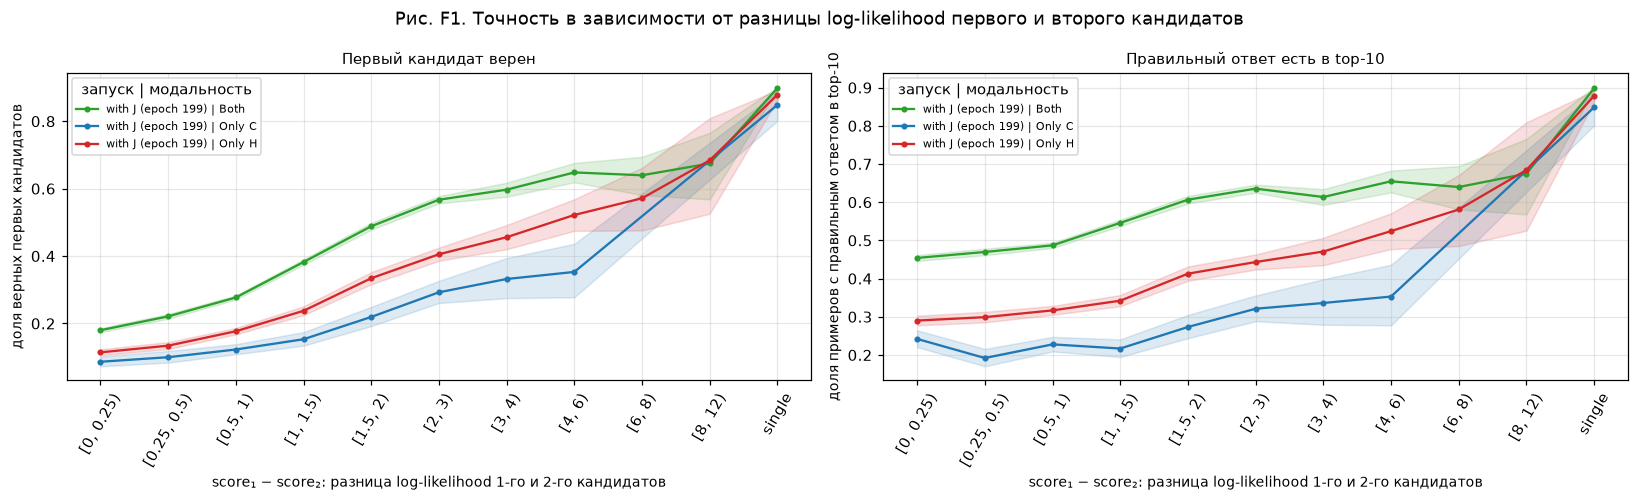

Таблица F1. Число примеров (count) и доля верных первых кандидатов (rate) по интервалам score₁ − score₂


count                                   rate              
run         with J (epoch 199)                     with J (epoch 199)              
modality                  Both    Only C    Only H               Both Only C Only H
margin_bin                                                                         
[0, 0.25)           15973.0000 1446.0000 4960.0000             0.1800 0.0864 0.1143
[0.25, 0.5)         13349.0000 1161.0000 4204.0000             0.2211 0.0999 0.1342
[0.5, 1)            20390.0000 1857.0000 6213.0000             0.2771 0.1228 0.1769
[1, 1.5)            13565.0000 1240.0000 4016.0000             0.3822 0.1532 0.2375
[1.5, 2)             9161.0000  816.0000 2645.0000             0.4884 0.2194 0.3342
[2, 3)               8255.0000  735.0000 2418.0000             0.5672 0.2925 0.4053
[3, 4)               2109.0000  238.0000  737.0000             0.5970 0.3319 0.4559
[4, 6)               1060.0000  136.0000  433.0000             0.6481 0.3529 0.5219
[6, 8)                272.0000       NaN  105.0000             0.6397    NaN 0.5714
[8, 12)                83.0000       NaN   38.0000             0.6747    NaN 0.6842
single              35762.0000  277.0000 1991.0000             0.8984 0.8484 0.8785

In [20]:
MARGIN_BINS = [0, 0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 12, np.inf]
labels = [f"[{a:g}, {b:g})" for a, b in zip(MARGIN_BINS[:-1], MARGIN_BINS[1:])]
df["margin_bin"] = pd.cut(df["margin"].replace(np.inf, np.nan), MARGIN_BINS, right=False, labels=labels).astype(str)
df.loc[np.isinf(df["margin"]), "margin_bin"] = "single"
df["margin_bin"] = pd.Categorical(df["margin_bin"], categories=labels + ["single"], ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
t = L.plot_rate(df, "first_exact", "margin_bin", axes[0], min_count=MIN_COUNT,
                title="Первый кандидат верен", ylabel="доля верных первых кандидатов")
L.plot_rate(df, "topn_exact", "margin_bin", axes[1], min_count=MIN_COUNT,
            title=f"Правильный ответ есть в top-{TOP_N}", ylabel=f"доля примеров с правильным ответом в top-{TOP_N}")
for ax in axes: ax.tick_params(axis="x", rotation=60); ax.legend(title=LEGEND_TITLE)
fig.suptitle("Рис. F1. Точность в зависимости от разницы log-likelihood первого и второго кандидатов")
plt.tight_layout(); plt.show()
print("Таблица F1. Число примеров (count) и доля верных первых кандидатов (rate) по интервалам score₁ − score₂")
display(t.pivot_table(index="margin_bin", columns=["run", "modality"], values=["count", "rate"], observed=False))

### Рис. F2. Распределение разницы score₁ − score₂ у верных и неверных первых кандидатов

- **Ось X** — score₁ − score₂ (значения > 20 собраны в 20).
- **Ось Y** — плотность: каждая кривая нормирована на площадь 1.
- Зелёная кривая — примеры с верным первым кандидатом, красная — с неверным.

Чем меньше кривые перекрываются, тем лучше разница отделяет верные ответы от неверных. Примеры `single` здесь не показаны; их доля указана в заголовке.

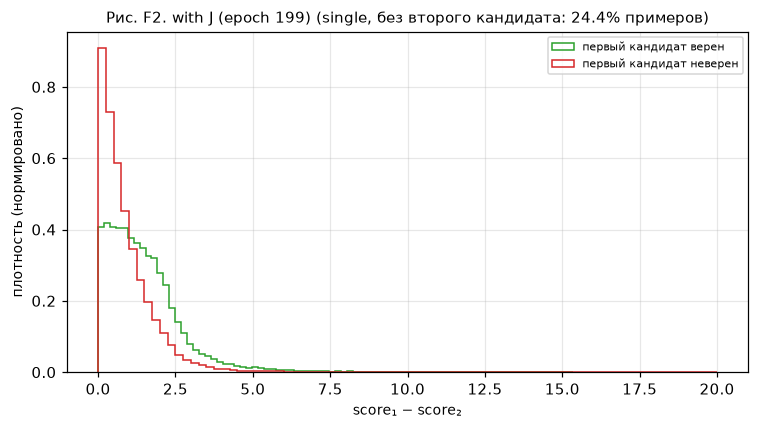

In [21]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(7 * len(RUNS), 4), squeeze=False)
for ax, (run, g) in zip(axes[0], df.groupby("run", sort=False)):
    finite = g[np.isfinite(g["margin"])]
    for ok, color in ((True, "#2ca02c"), (False, "#d62728")):
        ax.hist(finite.loc[finite.first_exact == ok, "margin"].clip(upper=20), bins=80, histtype="step", density=True,
                color=color, label="первый кандидат верен" if ok else "первый кандидат неверен")
    ax.set_xlabel("score₁ − score₂"); ax.set_ylabel("плотность (нормировано)")
    ax.set_title(f"Рис. F2. {run} (single, без второго кандидата: {np.isinf(g['margin']).mean():.1%} примеров)")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Таблицы F2, F3. Насколько каждый сигнал уверенности связан с правильностью

- **F2 — AUC.** Вероятность того, что у случайного верного примера сигнал выше, чем у случайного неверного. 0.5 — сигнал бесполезен, 1 — идеально разделяет. Ориентиры: 0.7 — умеренно, 0.8 — хорошо, 0.9 — отлично.
- **F3 — корреляция Спирмена** между сигналом и правильностью (1 — верен, 0 — нет). От −1 до 1, 0 — связи нет.

Строки — запуск и модальность, столбцы — сигналы (описаны в начале части F).

In [22]:
df["neg_unique"] = -df["topn_unique"]
signals = {"margin": "margin", "score1": "score1", "score1_per_token": "score1_per_token", "p_first": "p_first", "-n_unique": "neg_unique"}
report = L.confidence_report(df, signals, target="first_exact")
print("Таблица F2. AUC сигналов уверенности (0.5 = нет связи, 1 = идеально)")
display(report.pivot_table(index=["run", "modality"], columns="signal", values="auc"))
print("Таблица F3. Корреляция Спирмена сигнала с правильностью первого кандидата")
display(report.pivot_table(index=["run", "modality"], columns="signal", values="spearman"))

Таблица F2. AUC сигналов уверенности (0.5 = нет связи, 1 = идеально)


signal                       -n_unique  margin  p_first  score1  score1_per_token
run                modality                                                      
with J (epoch 199) Both         0.8509  0.8136   0.8393  0.8796            0.8608
                   Only C       0.8517  0.7073   0.7447  0.8894            0.8538
                   Only H       0.8369  0.7430   0.7796  0.8721            0.8275
                   Overall      0.8604  0.8073   0.8362  0.8862            0.8650

Таблица F3. Корреляция Спирмена сигнала с правильностью первого кандидата


signal                       -n_unique  margin  p_first  score1  score1_per_token
run                modality                                                      
with J (epoch 199) Both         0.6183  0.5505   0.5956  0.6576            0.6250
                   Only C       0.4843  0.2761   0.3259  0.5186            0.4712
                   Only H       0.5231  0.3730   0.4291  0.5710            0.5026
                   Overall      0.6271  0.5326   0.5829  0.6646            0.6281

### Рис. F3. Калибровка: можно ли читать p_first как вероятность

Примеры разбиты на 10 интервалов по `p_first`.
- **Ось X** — средний `p_first` в интервале.
- **Ось Y** — фактическая доля верных первых кандидатов в нём.
- **Пунктир** — идеальная калибровка: если модель говорит 0.8, то верно 80%. Точки ниже диагонали означают, что модель переоценивает уверенность.

**ECE** (в легенде) — средневзвешенное расстояние точек до диагонали: 0 — идеально, 0.1 — ошибка «вероятности» в среднем на 10 п.п.

`p_first` считается только по найденным кандидатам и не учитывает все остальные структуры, поэтому он заведомо завышен.

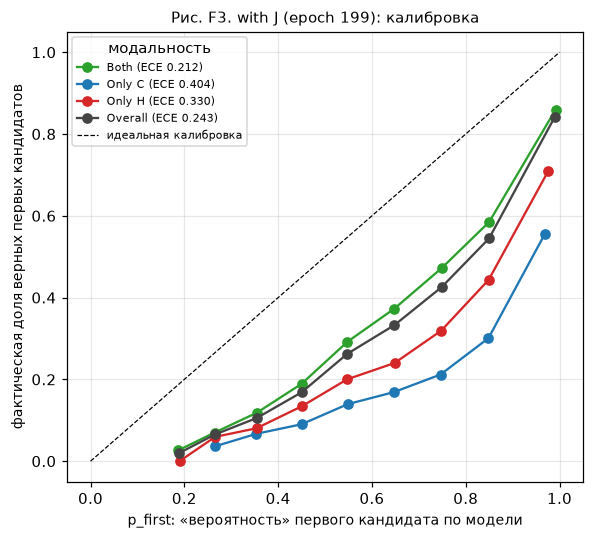

In [23]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(5.5 * len(RUNS), 5), squeeze=False)
for ax, (run, g) in zip(axes[0], df.groupby("run", sort=False)):
    for modality, gm in pd.concat([g, g.assign(modality="Overall")]).groupby("modality"):
        bins = pd.cut(gm["p_first"], np.linspace(0, 1, 11), include_lowest=True)
        r = gm.groupby(bins, observed=True).agg(p=("p_first", "mean"), acc=("first_exact", "mean"), n=("case", "size"))
        r = r[r.n >= MIN_COUNT]
        ece = L.expected_calibration_error(gm["p_first"], gm["first_exact"])
        ax.plot(r.p, r.acc, marker="o", color=L.MODALITY_COLORS[modality], label=f"{modality} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="идеальная калибровка")
    ax.set_xlabel("p_first: «вероятность» первого кандидата по модели"); ax.set_ylabel("фактическая доля верных первых кандидатов")
    ax.set_title(f"Рис. F3. {run}: калибровка"); ax.legend(title="модальность"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Рис. F4 и таблица F4. Если отвечать только на самые уверенные примеры (risk–coverage)

Примеры упорядочены по уверенности: по `margin`, примеры `single` считаются самыми уверенными. Берём только долю самых уверенных и смотрим, какая на них точность.
- **Ось X** — доля оставленных примеров (покрытие): 0.25 — оставили 25% самых уверенных, на остальные модель «отказывается отвечать».
- **Ось Y** — доля верных первых кандидатов среди оставленных.
- При покрытии 1.0 это обычная точность по всем примерам. Чем выше кривая слева, тем полезнее оценка уверенности.

**Таблица F4** — точность при покрытии 10%, 25%, 50%, 75% и 100%.

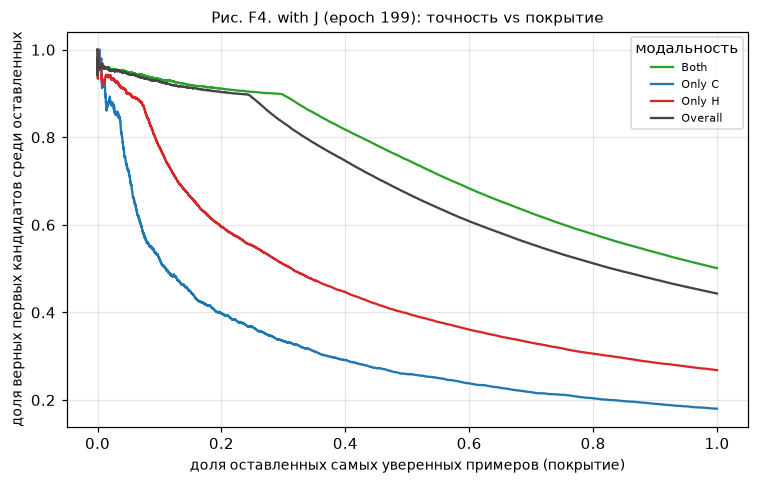

Таблица F4. Точность первого кандидата на доле самых уверенных примеров (столбцы — покрытие)


coverage                     0.1000  0.2500  0.5000  0.7500  1.0000
run                modality                                        
with J (epoch 199) Both      0.9331  0.9039  0.7484  0.6017  0.5011
                   Only C    0.5227  0.3669  0.2592  0.2119  0.1803
                   Only H    0.7770  0.5529  0.3977  0.3180  0.2682
                   Overall   0.9272  0.8905  0.6716  0.5329  0.4432

In [24]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(7 * len(RUNS), 4.5), squeeze=False)
rows = []
for ax, (run, g) in zip(axes[0], df.groupby("run", sort=False)):
    for modality, gm in pd.concat([g, g.assign(modality="Overall")]).groupby("modality"):
        conf = gm["margin"].replace(np.inf, 1e9)
        rc = L.risk_coverage(conf, gm["first_exact"])
        ax.plot(rc.coverage, rc.accuracy, color=L.MODALITY_COLORS[modality], label=modality)
        for cov in (0.1, 0.25, 0.5, 0.75, 1.0):
            rows.append({"run": run, "modality": modality, "coverage": cov,
                         "accuracy": rc.accuracy.iloc[max(int(cov * len(rc)) - 1, 0)]})
    ax.set_xlabel("доля оставленных самых уверенных примеров (покрытие)"); ax.set_ylabel("доля верных первых кандидатов среди оставленных")
    ax.set_title(f"Рис. F4. {run}: точность vs покрытие"); ax.legend(title="модальность"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Таблица F4. Точность первого кандидата на доле самых уверенных примеров (столбцы — покрытие)")
display(pd.DataFrame(rows).pivot_table(index=["run", "modality"], columns="coverage", values="accuracy"))

### Таблицы F5, F6. Жадный ответ vs лучший по log-likelihood из сэмплов

- **F5:** `agree` — доля примеров, где жадный ответ совпал с лучшим кандидатом из сэмплов; `top1_exact` — точность жадного ответа; `first_exact` — точность лучшего кандидата из сэмплов.
- **F6:** те же точности отдельно для примеров, где ответы совпали (`greedy_eq_first = True`) и где разошлись (`False`). Если при расхождении `first_exact` выше, то переранжирование сэмплов по log-likelihood лучше жадного декодирования.

In [25]:
if "top1_pred" in df:
    df["greedy_eq_first"] = df["top1_pred"] == df["first_pred"]
    print("Таблица F5. Совпадение жадного ответа и лучшего кандидата из сэмплов")
    display(df.groupby(["run", "modality"]).agg(agree=("greedy_eq_first", "mean"), top1_exact=("top1_exact", "mean"),
                                                first_exact=("first_exact", "mean")))
    print("Таблица F6. Точность, когда ответы совпали (True) и разошлись (False)")
    display(df.groupby(["run", "greedy_eq_first"])[["top1_exact", "first_exact"]].mean()
              .assign(count=df.groupby(["run", "greedy_eq_first"]).size()))

Таблица F5. Совпадение жадного ответа и лучшего кандидата из сэмплов


agree  top1_exact  first_exact
run                modality                                
with J (epoch 199) Both     0.8115      0.4783       0.5011
                   Only C   0.4499      0.1544       0.1803
                   Only H   0.5670      0.2383       0.2682

Таблица F6. Точность, когда ответы совпали (True) и разошлись (False)


top1_exact  first_exact   count
run                greedy_eq_first                                 
with J (epoch 199) False                0.0300       0.1268   39014
                   True                 0.5490       0.5490  116687